# Regression Modeling and Performance Evaluation
## Factors Associated with Five-Year Home Price Growth in California

**Name:** Sammy Sheu
**Course:** MSCS 634 — Big Data and Data Mining
**Deliverable:** 2 of 4 — Regression Modeling and Performance Evaluation

---

### The two questions this deliverable answers

1. **Which factors best predict five-year home price growth?**
2. **Given current conditions, what will California homes be worth in five years (2029)?**

### Input

D1 produced `data/processed/ca_zip_housing_panel_clean.csv` — **7,487 rows × 28 columns**, one row per
California ZIP code per base year (2016–2020), with the *realized* five-year growth that followed.
**This notebook does not re-clean anything.** Every cleaning decision was made and justified in D1.

### A note on language

This is **observational** data. Nothing here identifies a cause. Throughout, features are described
as **associated with** or **predictive of** five-year growth — never as *causing* it. A ZIP code's
affordability ratio and its subsequent price growth move together; which one moves the other, or
whether a third factor moves both, is not something a regression on this panel can establish.

### What the reader should expect to find

This notebook reports a **model that fails on its out-of-time test set** — every model, including the
trivial baseline, posts a negative test R². That result is **not a bug**, and it is not hidden. It is
diagnosed in Section 5, and the diagnosis turns out to be the most informative finding in the
project: the five-year growth *level* is set by the macro regime, which cross-sectional ZIP-code
features cannot see, while the *ranking* of ZIP codes against each other is genuinely learnable.

---
## 0. Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

# --- Plot theme (carried over from D1, so the two deliverables read as one document) -------------
#   ORDINAL (base year 2016 -> 2020): one blue hue, light -> dark.
#   CATEGORICAL (models): a fixed hue order, never cycled.
YEAR_COLORS = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]
CATEGORICAL = ["#52514e", "#2a78d6", "#1baf7a", "#eda100", "#4a3aa7"]
BLUE, ACCENT, GRAY, GREEN = "#2a78d6", "#eb6834", "#52514e", "#1baf7a"

mpl.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c3", "axes.labelcolor": "#0b0b0b",
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": "#e7e6e2", "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "text.color": "#0b0b0b", "xtick.color": GRAY, "ytick.color": GRAY,
    "font.size": 10, "figure.dpi": 110, "savefig.bbox": "tight",
    "legend.frameon": False,
})

def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", dpi=150)

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.3 | numpy 2.5.1


---
# 1. Loading D1's cleaned panel, and the feature engineering this stage adds

## 1.1 The panel

In [2]:
TARGET = "future_5yr_growth_pct"

panel = pd.read_csv(PROC / "ca_zip_housing_panel_clean.csv", dtype={"zip_code": str})
print(f"{len(panel):,} rows x {panel.shape[1]} columns")
print("\nrows per base year:")
print(panel["base_year"].value_counts().sort_index().to_string())
print(f"\nnulls in target: {panel[TARGET].isna().sum()}")
panel.head(3)

7,487 rows x 28 columns

rows per base year:
base_year
2016    1452
2017    1496
2018    1500
2019    1511
2020    1528

nulls in target: 0


,zip_code,base_year,city,county,current_home_value,home_value_1yr_growth_pct,home_value_3yr_growth_pct,median_household_income,median_gross_rent,population,population_growth_pct,unemployment_rate,bachelor_degree_pct,mortgage_rate,price_to_income_ratio,price_to_rent_ratio,housing_units,zori_rent,zori_rent_available,inventory_per_1k_housing_units,new_listings_per_1k_housing_units,price_cut_pct,list_to_value_ratio,listings_available,is_growth_outlier,is_value_outlier,future_5yr_home_value,future_5yr_growth_pct
0,90011,2016,Los Angeles,Los Angeles County,"292,266.880",9.888,30.875,"31,684.000","1,011.000","104,762.000",3.190,8.659,3.579,3.654,9.224,24.091,"24,511.000",NaN,0,NaN,NaN,NaN,NaN,0,0,0,"554,428.390",89.699
1,90650,2016,Norwalk,Los Angeles County,"395,687.204",6.299,17.631,"61,050.000","1,384.000","106,360.000",0.961,7.951,15.973,3.654,6.481,23.825,"28,528.000",NaN,0,NaN,NaN,NaN,NaN,0,0,0,"659,410.786",66.650
2,91331,2016,Los Angeles,Los Angeles County,"353,540.080",8.687,24.369,"53,714.000","1,315.000","101,536.000",4.115,11.788,10.359,3.654,6.582,22.404,"23,277.000",NaN,0,NaN,NaN,NaN,NaN,0,0,0,"631,069.440",78.500


## 1.2 Three engineered features

D1's 12 core features are carried forward unchanged. D2 adds three, all built around one idea:
**what a home actually costs a household per month**, rather than what it costs in total.

| New feature | Definition |
|---|---|
| `estimated_monthly_mortgage` | Standard amortization: 20% down, 30-year fixed at that year's rate |
| `mortgage_to_income_ratio` | Estimated monthly payment ÷ monthly median household income |
| `rent_to_income_ratio` | Annual median gross rent ÷ median household income |

`mortgage_to_income_ratio` is the interesting one. `price_to_income_ratio` (from D1) compares a
price to an income and ignores financing entirely — so a $700k home looks identical at a 3%
mortgage rate and at a 7% one, even though the monthly payment differs by roughly 45%.
`mortgage_to_income_ratio` **fuses price, interest rate and income into a single affordability
measure**, and the affordability-constraint hypothesis — that markets already priced beyond what
local incomes can carry subsequently grow more slowly — is this project's central testable claim.

Whether adding the financing ingredient actually buys anything is tested immediately below, and the
answer is not the expected one.

The amortization formula:

$$ M = P \cdot \frac{r(1+r)^{n}}{(1+r)^{n}-1} \qquad P = 0.80 \times \text{home value},\quad
r = \frac{\text{annual rate}}{1200},\quad n = 360 $$

In [3]:
def engineer(d: pd.DataFrame) -> pd.DataFrame:
    """Add the three D2 features. Applied identically to the panel and to the 2024 forecast frame."""
    d = d.copy()
    r = d["mortgage_rate"] / 100 / 12          # monthly rate
    n = 360                                     # 30-year term, in months
    principal = d["current_home_value"] * 0.80  # 20% down

    d["estimated_monthly_mortgage"] = principal * r * (1 + r) ** n / ((1 + r) ** n - 1)
    d["mortgage_to_income_ratio"] = (
        d["estimated_monthly_mortgage"] / (d["median_household_income"] / 12)
    )
    d["rent_to_income_ratio"] = d["median_gross_rent"] * 12 / d["median_household_income"]
    return d


panel = engineer(panel)

NEW = ["estimated_monthly_mortgage", "mortgage_to_income_ratio", "rent_to_income_ratio"]
panel[NEW].describe().T

,count,mean,std,min,25%,50%,75%,max
estimated_monthly_mortgage,"7,487.000","2,367.949","1,831.064",166.708,"1,194.320","1,914.870","2,866.125","24,882.816"
mortgage_to_income_ratio,"7,487.000",0.373,0.199,0.052,0.248,0.325,0.446,3.749
rent_to_income_ratio,"7,487.000",0.250,0.096,0.068,0.212,0.243,0.277,6.365


In [4]:
# How the engineered features relate to the outcome -- pooled, and inside each base year.
compare = ["price_to_income_ratio", "price_to_rent_ratio"] + NEW
rows = []
for c in compare:
    row = {"feature": c, "pooled r": panel[c].corr(panel[TARGET])}
    for y, g in panel.groupby("base_year"):
        row[str(y)] = g[c].corr(g[TARGET])
    rows.append(row)
corr_tbl = pd.DataFrame(rows).set_index("feature")
print("Correlation with future_5yr_growth_pct")
print(corr_tbl.round(3).to_string())

Correlation with future_5yr_growth_pct
                            pooled r   2016   2017   2018   2019   2020
feature                                                                
price_to_income_ratio         -0.286 -0.328 -0.322 -0.413 -0.288 -0.193
price_to_rent_ratio           -0.305 -0.376 -0.386 -0.415 -0.278 -0.135
estimated_monthly_mortgage    -0.219 -0.317 -0.303 -0.322 -0.117  0.027
mortgage_to_income_ratio      -0.268 -0.328 -0.322 -0.413 -0.288 -0.193
rent_to_income_ratio           0.047  0.202  0.031  0.041  0.006 -0.086


**Reading this table — and it contains an unwelcome surprise worth stating immediately.**

The good news first: `mortgage_to_income_ratio` correlates **−0.268** with five-year growth pooled, and
its sign is **negative inside every single base year** (−0.328, −0.322, −0.413, −0.288, −0.193). A
relationship that survives within every year is a genuine cross-sectional association, not an artifact
of the five years having different average growth rates.

**Now the surprise: those five within-year numbers are *identical* to `price_to_income_ratio`'s.** Not
similar — identical, to three decimals. That is not a coincidence, and the reason is worth spelling out:

> `mortgage_rate` is **constant within a base year**. So within any one year,
> `estimated_monthly_mortgage = k · current_home_value` for a constant *k*, and therefore
> `mortgage_to_income_ratio = k · price_to_income_ratio`. Correlation is invariant to positive scaling,
> so the two features **must** have the same within-year correlation with anything.

**The engineered feature adds no cross-sectional information.** Inside any single year it is a
rescaling of a feature D1 already had. All it changes is the *between-year* comparison — it rescales
2018 differently from 2020 — and pooled that makes the correlation slightly **weaker** (−0.268 vs
−0.286), because it mixes in exactly the between-year variation that Section 5 will show to be
poisonous.

This is a negative result about a feature the plan expected to be the most interesting one, and it is
the first appearance of the theme that runs through the whole deliverable: **a variable that is constant
within a time period cannot rank the units inside it.** The feature is retained — Section 6 finds it
carries the largest standardized Ridge coefficient in the model — but it must be read as *a
year-rescaled `price_to_income_ratio`*, not as an independent affordability measurement.

`price_to_rent_ratio` remains the strongest single affordability correlate pooled (**−0.305**), and it
is genuinely distinct: its within-year profile (−0.376, −0.386, −0.415, −0.278, −0.135) differs from the
price-to-income pair.

`rent_to_income_ratio` is close to a null (**+0.047** pooled, and it changes sign across years) and is
retained mainly as a control: it separates "expensive to *buy* relative to income" from "expensive to
*rent* relative to income," and only the first turns out to predict anything.

---
# 2. Leakage prevention

**This is the section that determines whether every number below means anything.**

## 2.1 Why a random train/test split would be fraudulent here

D1 flagged it: the five outcome windows **overlap**. Base year 2016 measures growth over 2017–2021;
base year 2017 measures 2018–2022. For the same ZIP code those two rows share **four of five years of
price history**, and they share most of their features too — ACS 5-year estimates for adjacent years
are built from overlapping survey samples.

A random split therefore drops **near-duplicates of the test rows into the training set**. The model
does not learn a housing relationship; it learns to recognise ZIP codes it has already seen, and
returns a high R² that would not survive contact with a genuinely unseen market.

**7,487 rows are not 7,487 independent observations.**

## 2.2 The split actually used — by time

| Split | Base years | Purpose |
|---|---|---|
| **Train** | 2016, 2017, 2018 | Fit |
| **Validation** | 2019 | Hyperparameter selection, model choice |
| **Test** | 2020 | Touched once, at the end |

This mirrors the real task — *use earlier markets to predict later outcomes* — and it is the only
split under which the 2029 forecast in Section 8 is an honest exercise rather than a circular one.

Cross-validation uses **`GroupKFold` grouped on `base_year`** (leave-one-base-year-out over the three
training years). Plain `KFold` appears nowhere in this notebook.

## 2.3 Columns removed before fitting

| Dropped | Reason |
|---|---|
| `future_5yr_home_value` | **The target restated.** `growth = (future/current − 1)·100`. Leaving it in makes R² ≈ 1.0 and the model worthless |
| `base_year` | It *is* the split variable; as a feature it would let the model read the macro regime off an index column |
| `zip_code`, `city`, `county` | Identifiers — memorisation, not prediction |
| `zori_rent`, `zori_rent_available` | 78% missing, non-randomly (D1 §7) |
| `listings_*` | Structurally absent before 2018. Handled separately in the contained experiment of Section 7 |
| `is_growth_outlier`, `is_value_outlier` | Built **from the target**. Using them is leakage |
| `housing_units` | Retained only as the denominator for the Section 7 listings normalisation |

The last one is worth pausing on. `is_growth_outlier` was computed in D1 by applying an IQR rule to
`future_5yr_growth_pct` itself. It looks like an innocuous data-quality flag; it is a partial answer key.

In [5]:
FEATURES = [
    # --- D1 core (12) ---
    "current_home_value", "home_value_1yr_growth_pct", "home_value_3yr_growth_pct",
    "median_household_income", "median_gross_rent", "population", "population_growth_pct",
    "unemployment_rate", "bachelor_degree_pct", "mortgage_rate",
    "price_to_income_ratio", "price_to_rent_ratio",
    # --- D2 engineered (3) ---
    "estimated_monthly_mortgage", "mortgage_to_income_ratio", "rent_to_income_ratio",
]

LEAKY = ["future_5yr_home_value", "is_growth_outlier", "is_value_outlier"]
assert not any(c in FEATURES for c in LEAKY), "a target-derived column reached the feature matrix"
assert "base_year" not in FEATURES, "base_year must not be a feature -- it is the split variable"

TRAIN_YEARS, VAL_YEAR, TEST_YEAR = [2016, 2017, 2018], 2019, 2020

train = panel[panel["base_year"].isin(TRAIN_YEARS)]
val   = panel[panel["base_year"] == VAL_YEAR]
test  = panel[panel["base_year"] == TEST_YEAR]

X_train, y_train = train[FEATURES], train[TARGET]
X_val,   y_val   = val[FEATURES],   val[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]
groups = train["base_year"]                 # <- CV groups, never a feature

print(f"features          {len(FEATURES)}")
print(f"train  {TRAIN_YEARS}  {len(train):>5,} rows   mean growth {y_train.mean():6.2f}%")
print(f"val    [{VAL_YEAR}]              {len(val):>5,} rows   mean growth {y_val.mean():6.2f}%")
print(f"test   [{TEST_YEAR}]              {len(test):>5,} rows   mean growth {y_test.mean():6.2f}%")

# No ZIP-year appears in two splits, and no split shares a base year with another.
assert set(train["base_year"]) & set(val["base_year"]) == set()
assert set(train["base_year"]) & set(test["base_year"]) == set()
print("\nleakage assertions passed: splits share no base year, no target-derived feature present")

features          15
train  [2016, 2017, 2018]  4,448 rows   mean growth  47.96%
val    [2019]              1,511 rows   mean growth  38.15%
test   [2020]              1,528 rows   mean growth  24.31%

leakage assertions passed: splits share no base year, no target-derived feature present


> **Already visible in the split summary, and it decides the whole deliverable:**
> mean growth is **47.96%** in training, **38.15%** in validation and **24.31%** in test. The thing
> being predicted has a *different average* in each split, by a margin far larger than any model's
> error bar. Section 5 shows what that does.

---
# 3. Models

| Model | Why it is here |
|---|---|
| **Baseline** — predict the training mean for every ZIP | Without it an R² of 0.35 is uninterpretable. It is also the honest reference for *"is this model worth anything at all?"* |
| **Ridge** | Interpretable signed coefficients. D1 measured income ↔ rent at **+0.84** and education ↔ income at **+0.76**; under plain OLS that collinearity makes coefficients unstable and sign-flippy, so the *explanation* becomes worthless even when predictions are fine. Ridge's L2 penalty shares weight across correlated predictors instead of arbitrarily crowning one |
| **Random Forest** | Captures nonlinearity and interactions; supplies a second, independent view of feature importance |
| **Gradient Boosting** | Usually the strongest of the three on tabular data. XGBoost is deliberately skipped — an extra dependency and more tuning for little gain at this size |

## 3.1 Scaling belongs inside the Pipeline

Ridge is scale-sensitive: `median_household_income` runs to ~250,000 and `unemployment_rate` to ~30, so
without standardisation the penalty falls almost entirely on the small-scale features.

Fitting a `StandardScaler` on the full dataset *before* splitting is a **subtle leak** — the test
rows' means and standard deviations bleed into the training transform. Wrapping the scaler in a
`Pipeline` makes `cross_val_predict` refit it on each training fold alone. Trees are scale-invariant,
so they take the raw features.

In [6]:
def fit_ridge_alpha(X, y, groups, alphas=np.logspace(-2, 4, 25)):
    """Choose Ridge's alpha by leave-one-base-year-out CV RMSE. No plain KFold."""
    gkf = GroupKFold(n_splits=3)
    scores = []
    for a in alphas:
        pipe = Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=a))])
        pred = cross_val_predict(pipe, X, y, cv=gkf, groups=groups)
        scores.append(np.sqrt(mean_squared_error(y, pred)))
    best = alphas[int(np.argmin(scores))]
    return best, pd.Series(scores, index=np.round(alphas, 3))


best_alpha, alpha_curve = fit_ridge_alpha(X_train, y_train, groups)
print(f"selected Ridge alpha = {best_alpha:,.1f}   (CV RMSE {alpha_curve.min():.3f})")
print("\nCV RMSE across the alpha grid (every 4th):")
print(alpha_curve.iloc[::4].round(3).to_string())

selected Ridge alpha = 1,778.3   (CV RMSE 17.763)

CV RMSE across the alpha grid (every 4th):
0.010        20.054
0.100        20.028
1.000        19.914
10.000       19.780
100.000      19.274
1,000.000    17.800
10,000.000   19.428


The selected penalty is **very large (α ≈ 1,778)**. That is itself a diagnostic: with 15 features of
which roughly six are near-restatements of one another, the cross-validated optimum is to shrink
nearly all of them hard. Ridge is telling us the panel supports far fewer effective degrees of
freedom than it has columns.

In [7]:
def make_models(alpha):
    return {
        "Baseline (mean)": DummyRegressor(strategy="mean"),
        "Ridge": Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=alpha))]),
        "Random Forest": RandomForestRegressor(
            n_estimators=400, min_samples_leaf=5, max_features=0.5,
            random_state=RANDOM_STATE, n_jobs=-1),
        "Gradient Boosting": GradientBoostingRegressor(
            n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8,
            random_state=RANDOM_STATE),
    }

models = make_models(best_alpha)
for name, m in models.items():
    print(f"{name:<20} {type(m).__name__}")

Baseline (mean)      DummyRegressor
Ridge                Pipeline
Random Forest        RandomForestRegressor
Gradient Boosting    GradientBoostingRegressor


---
# 4. Evaluation

Every model is scored with **R², MSE, RMSE and MAE**, plus a **cross-validated RMSE** obtained by
leave-one-base-year-out `GroupKFold` on the training years.

In [8]:
def metrics(y, pred) -> dict:
    mse = mean_squared_error(y, pred)
    return {"R2": r2_score(y, pred), "MSE": mse,
            "RMSE": np.sqrt(mse), "MAE": mean_absolute_error(y, pred)}


def evaluate(models, X_tr, y_tr, g, X_v, y_v, X_te, y_te):
    gkf = GroupKFold(n_splits=3)
    rows, fitted, preds = [], {}, {}
    for name, model in models.items():
        cv_pred = cross_val_predict(model, X_tr, y_tr, cv=gkf, groups=g)
        cv_rmse = np.sqrt(mean_squared_error(y_tr, cv_pred))

        model.fit(X_tr, y_tr)
        fitted[name] = model
        p_tr, p_v, p_te = model.predict(X_tr), model.predict(X_v), model.predict(X_te)
        preds[name] = {"train": p_tr, "val": p_v, "test": p_te}

        mv, mt, mtr = metrics(y_v, p_v), metrics(y_te, p_te), metrics(y_tr, p_tr)
        rows.append({
            "Model": name, "CV RMSE": cv_rmse, "Train R2": mtr["R2"],
            "Val RMSE": mv["RMSE"], "Val MAE": mv["MAE"], "Val R2": mv["R2"],
            "Test MSE": mt["MSE"], "Test RMSE": mt["RMSE"],
            "Test MAE": mt["MAE"], "Test R2": mt["R2"],
        })
    return pd.DataFrame(rows).set_index("Model"), fitted, preds


results, fitted, preds = evaluate(models, X_train, y_train, groups, X_val, y_val, X_test, y_test)
results.round(3)

,CV RMSE,Train R2,Val RMSE,Val MAE,Val R2,Test MSE,Test RMSE,Test MAE,Test R2
Model,,,,,,,,,
Baseline (mean),22.330,0.000,21.382,15.962,-0.266,857.155,29.277,24.776,-1.875
Ridge,17.763,0.319,20.973,15.877,-0.218,"1,641.709",40.518,37.172,-4.506
Random Forest,18.055,0.801,19.425,14.642,-0.045,"1,147.395",33.873,29.501,-2.848
Gradient Boosting,17.708,0.702,19.041,14.328,-0.004,"1,259.907",35.495,31.423,-3.226


## 4.1 What this table says

**Read the validation column first, then the test column, because they tell opposite stories.**

On **cross-validation and validation**, the models behave exactly as expected. Every ML model beats
the baseline's CV RMSE of 22.33 — Gradient Boosting reaches **17.71**, a **21% error reduction**, and
Ridge and Random Forest land within a whisker of it. On the 2019 validation year the ordering holds:
Gradient Boosting 19.04 vs. baseline 21.38.

On the **2020 test year, every model collapses.** Test R² is **−1.88 for the baseline, −2.85 for
Random Forest, −3.23 for Gradient Boosting, and −4.51 for Ridge.**

Three things follow immediately, and they should be stated before any explanation is attempted:

1. **The baseline is also catastrophically negative (−1.88).** Whatever went wrong is not a modelling
   error — predicting a single constant fails just as badly. This is the single most useful number in
   the table, and it is exactly why the plan insisted on including a baseline.
2. **Ridge is the *worst* model on test despite being competitive on validation.** A linear model
   extrapolates; the tree models cannot. Section 5.2 identifies precisely which feature it
   extrapolated on.
3. **Random Forest's train R² of 0.80 against a CV R² near 0.35** is ordinary tree-ensemble
   memorisation of the training rows, not the cause of the test failure.

**An R² near 0.9 anywhere in this notebook would have been evidence of leakage, not success.**
D1 predicted a realistic ceiling of R² ≈ 0.3–0.5, and the CV numbers sit right at the bottom of that
range. What no one predicted was the *sign* of the test result.

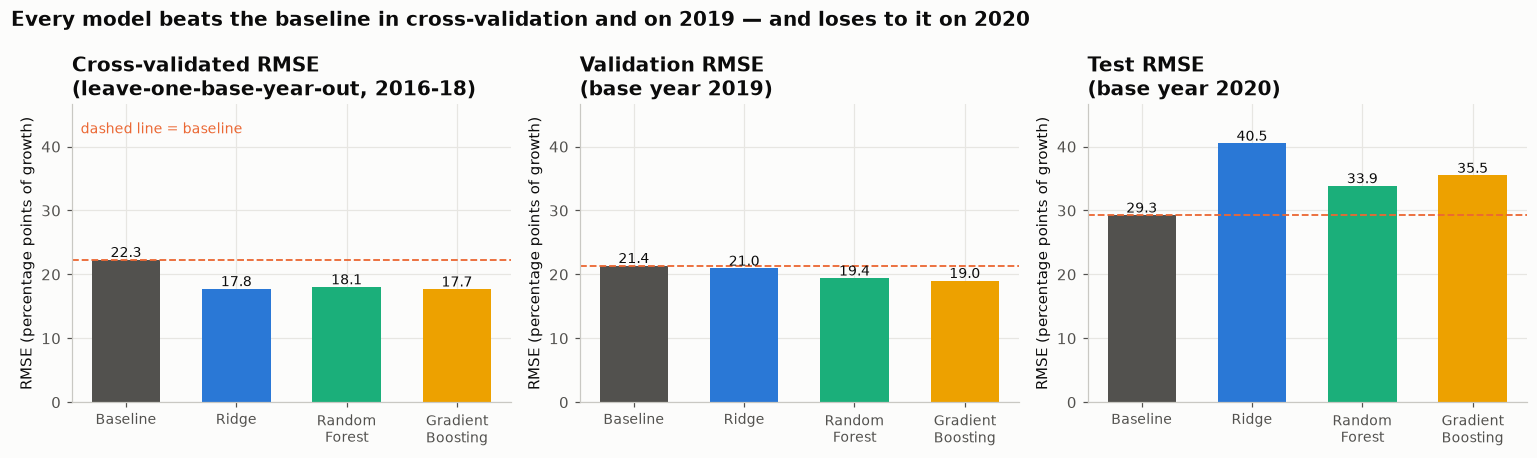

In [9]:
# ---- Figure 1: metric comparison ---------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
order = list(results.index)
colors = CATEGORICAL[:len(order)]

for ax, col, title in zip(
    axes,
    ["CV RMSE", "Val RMSE", "Test RMSE"],
    ["Cross-validated RMSE\n(leave-one-base-year-out, 2016-18)",
     "Validation RMSE\n(base year 2019)",
     "Test RMSE\n(base year 2020)"],
):
    ax.bar(range(len(order)), results.loc[order, col], color=colors, width=0.62)
    for i, v in enumerate(results.loc[order, col]):
        ax.text(i, v + 0.4, f"{v:.1f}", ha="center", fontsize=9)
    ax.axhline(results.loc["Baseline (mean)", col], color=ACCENT, ls="--", lw=1.2)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([o.replace(" (mean)", "").replace(" ", "\n") for o in order], fontsize=9)
    ax.set_title(title)
    ax.set_ylabel("RMSE (percentage points of growth)")
    ax.set_ylim(0, max(results["Test RMSE"]) * 1.15)

axes[0].text(0.02, 0.94, "dashed line = baseline", transform=axes[0].transAxes,
             color=ACCENT, fontsize=9, va="top")
fig.suptitle("Every model beats the baseline in cross-validation and on 2019 — and loses to it on 2020",
             x=0.005, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "fig01_model_comparison")
plt.show()

**Figure 1.** The first two panels are the result a well-behaved model produces: bars below the dashed
baseline line. The third panel inverts it — on the 2020 test year every bar sits *above* the baseline,
and Ridge is nearly 40% worse than doing nothing at all.

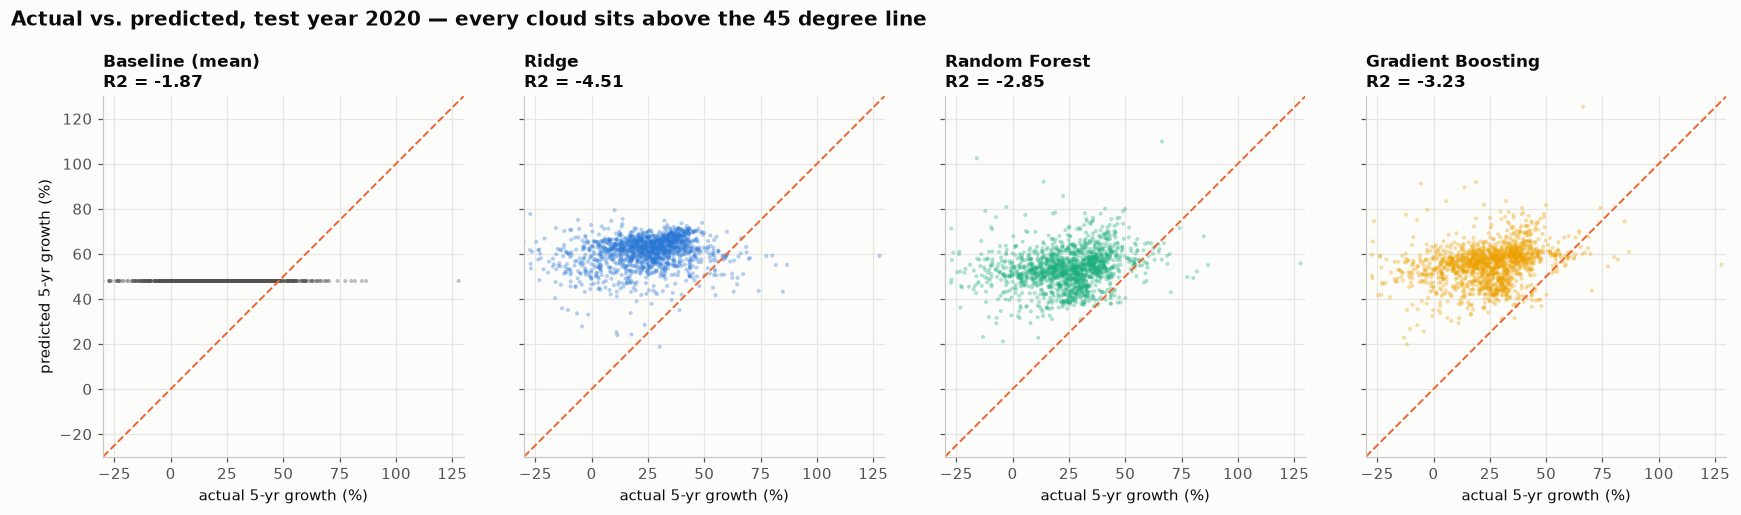

In [10]:
# ---- Figure 2: actual vs predicted, test year --------------------------------------------------
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), sharex=True, sharey=True)
lo, hi = -30, 130
for ax, (name, color) in zip(axes, zip(order, colors)):
    p = preds[name]["test"]
    ax.scatter(y_test, p, s=7, alpha=0.35, color=color, edgecolor="none")
    ax.plot([lo, hi], [lo, hi], color=ACCENT, lw=1.3, ls="--")
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_aspect("equal")
    ax.set_title(f"{name}\nR2 = {results.loc[name, 'Test R2']:.2f}", fontsize=11)
    ax.set_xlabel("actual 5-yr growth (%)")
axes[0].set_ylabel("predicted 5-yr growth (%)")
fig.suptitle("Actual vs. predicted, test year 2020 — every cloud sits above the 45 degree line",
             x=0.005, y=1.04, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "fig02_actual_vs_predicted")
plt.show()

**Figure 2.** The diagnosis is visible without any statistics. The point clouds are not scattered
*around* the 45° line — they sit **entirely above it**. The models are not noisy; they are
**systematically, uniformly too high**. That is the signature of a *level* error, not a *relationship*
error.

Note also how little the clouds tilt. Ridge's cloud is nearly horizontal — it predicts roughly the
same value for every ZIP code in 2020, just the wrong one.

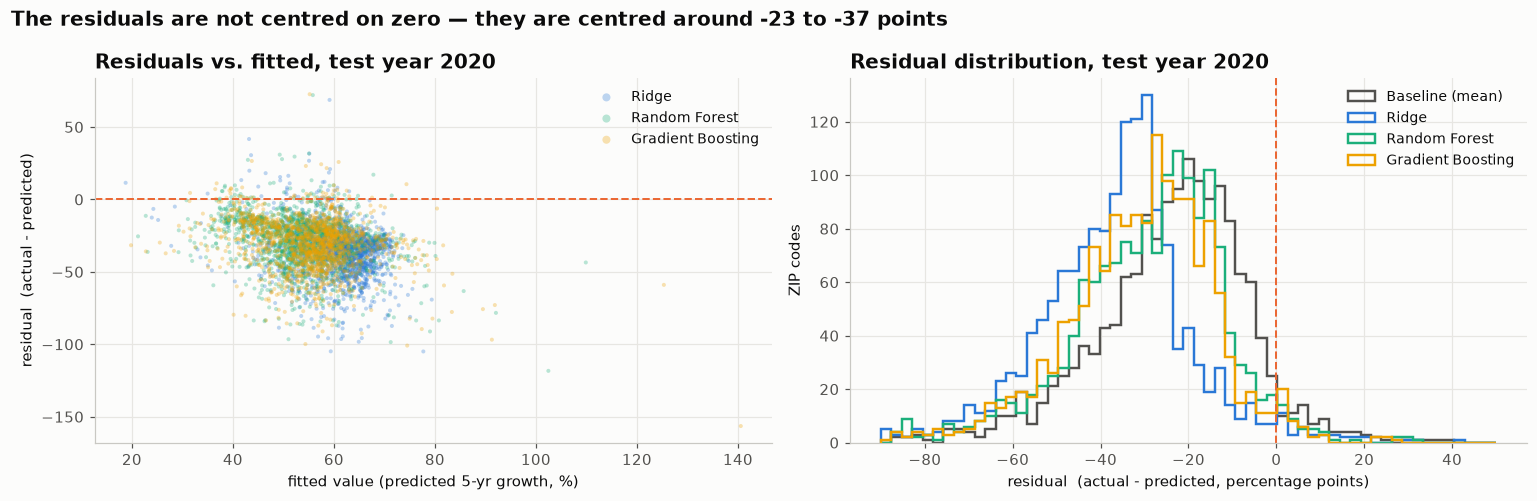

In [11]:
# ---- Figure 3 & 4: residual diagnostics --------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

ax = axes[0]
for name, color in zip(order[1:], colors[1:]):
    p = preds[name]["test"]
    ax.scatter(p, y_test - p, s=7, alpha=0.3, color=color, edgecolor="none", label=name)
ax.axhline(0, color=ACCENT, lw=1.3, ls="--")
ax.set_xlabel("fitted value (predicted 5-yr growth, %)")
ax.set_ylabel("residual  (actual - predicted)")
ax.set_title("Residuals vs. fitted, test year 2020")
ax.legend(fontsize=9, markerscale=2)

ax = axes[1]
bins = np.linspace(-90, 50, 60)
for name, color in zip(order, colors):
    ax.hist(y_test - preds[name]["test"], bins=bins, histtype="step", lw=1.6,
            color=color, label=name)
ax.axvline(0, color=ACCENT, lw=1.3, ls="--")
ax.set_xlabel("residual  (actual - predicted, percentage points)")
ax.set_ylabel("ZIP codes")
ax.set_title("Residual distribution, test year 2020")
ax.legend(fontsize=9)

fig.suptitle("The residuals are not centred on zero — they are centred around -23 to -37 points",
             x=0.005, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "fig03_residuals")
plt.show()

**Figures 3 and 4.** A healthy residual plot is a formless band centred on zero. This one is a band of
roughly the right *shape* — no funnel, no curvature, so the functional form is not obviously wrong —
translated bodily **downwards**. The residual histograms are near-symmetric bells, but every one of
them is centred well to the left of zero.

The models are internally consistent and externally mis-calibrated. That is a very specific kind of
failure, and Section 5 quantifies it.

---
# 5. Diagnosing the out-of-time failure

**This is the most important section of the deliverable.** An honest analysis of *why* a model failed
out-of-time is worth more than a suspiciously good number.

## 5.1 Decomposing the error into bias and spread

If the residuals are merely shifted, then subtracting their mean should restore an ordinary error
level. Formally, test MSE decomposes as

$$ \text{MSE} = \underbrace{(\bar{\hat{y}} - \bar{y})^{2}}_{\text{squared bias — the level error}}
   \; + \; \underbrace{\text{MSE}_{\text{debiased}}}_{\text{everything else}} $$

In [12]:
rows = []
for name in order:
    p = preds[name]["test"]
    bias = p.mean() - y_test.mean()
    p_debiased = p - bias                        # remove the level shift only; ranking untouched
    sp = spearmanr(y_test, p).statistic if np.std(p) > 1e-9 else np.nan
    rows.append({
        "Model": name,
        "Test RMSE": np.sqrt(mean_squared_error(y_test, p)),
        "bias (pred - actual)": bias,
        "share of MSE from bias": bias ** 2 / mean_squared_error(y_test, p),
        "debiased RMSE": np.sqrt(mean_squared_error(y_test, p_debiased)),
        "debiased R2": r2_score(y_test, p_debiased),
        "Spearman rank corr": sp,
    })
decomp = pd.DataFrame(rows).set_index("Model")
print(f"standard deviation of actual 2020 growth: {y_test.std():.2f} percentage points\n")
decomp.round(3)

standard deviation of actual 2020 growth: 17.27 percentage points



,Test RMSE,bias (pred - actual),share of MSE from bias,debiased RMSE,debiased R2,Spearman rank corr
Model,,,,,,
Baseline (mean),29.277,23.643,0.652,17.267,0.000,NaN
Ridge,40.518,36.560,0.814,17.466,-0.023,0.209
Random Forest,33.873,28.955,0.731,17.579,-0.036,0.248
Gradient Boosting,35.495,30.983,0.762,17.319,-0.006,0.314


**This is the whole story in one table.**

- **65–81% of every model's test MSE is pure bias** — a constant level error, identical for every ZIP
  code, with nothing to do with which ZIP code it is. (Baseline 65%, Random Forest 73%, Gradient
  Boosting 76%, Ridge 81%.)
- Once that single constant is removed, **debiased RMSE lands at 17.3–17.6** against an actual standard
  deviation of **17.27**. Debiased R² is approximately **zero**. Having corrected the level, the models
  explain essentially none of the remaining ZIP-to-ZIP variation in 2020.
- But **Spearman rank correlation is +0.21 to +0.31 and positive for every model.** The *ordering* of
  ZIP codes carries real signal even though the *level* is badly wrong.

Two distinct findings, and they must not be conflated:

> **The models cannot predict how much California housing appreciated. They can, weakly, predict which
> California ZIP codes appreciated more than others.**

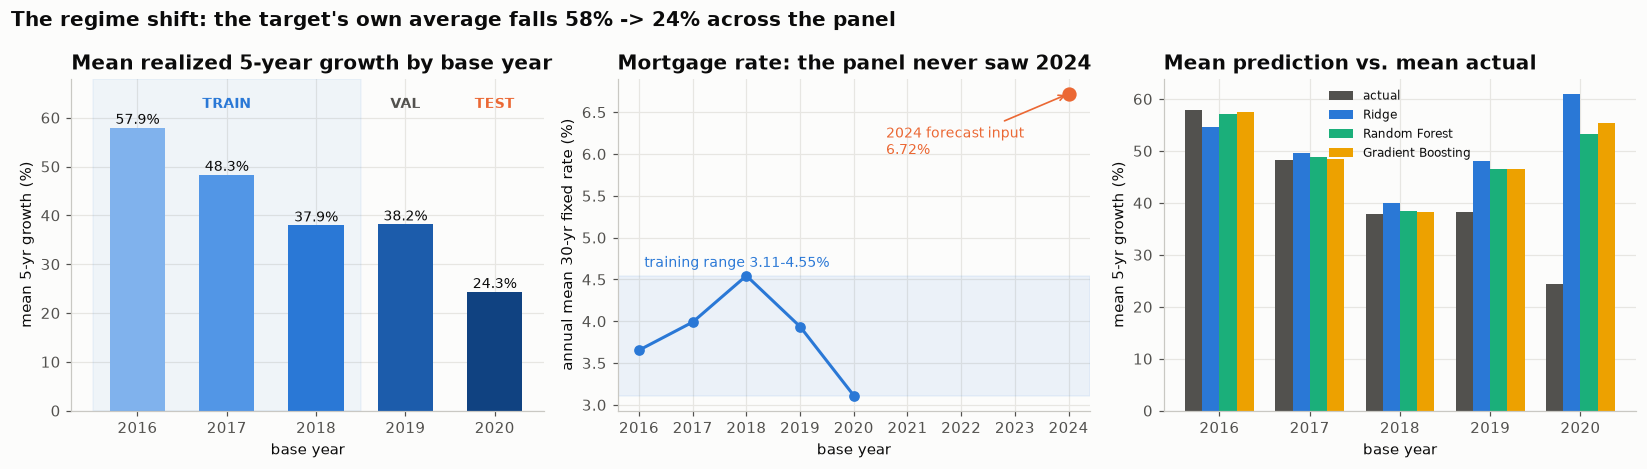

In [13]:
# ---- Figure 5: the regime shift ----------------------------------------------------------------
by_year = panel.groupby("base_year").agg(
    mean_growth=(TARGET, "mean"), median_growth=(TARGET, "median"),
    mortgage_rate=("mortgage_rate", "first")).reset_index()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

ax = axes[0]
ax.bar(by_year["base_year"].astype(str), by_year["mean_growth"], color=YEAR_COLORS, width=0.62)
for i, v in enumerate(by_year["mean_growth"]):
    ax.text(i, v + 0.8, f"{v:.1f}%", ha="center", fontsize=9)
ax.axvspan(-0.5, 2.5, color=BLUE, alpha=0.06)
ax.text(1.0, 62, "TRAIN", ha="center", color=BLUE, fontweight="bold", fontsize=9)
ax.text(3.0, 62, "VAL", ha="center", color=GRAY, fontweight="bold", fontsize=9)
ax.text(4.0, 62, "TEST", ha="center", color=ACCENT, fontweight="bold", fontsize=9)
ax.set_ylim(0, 68)
ax.set_title("Mean realized 5-year growth by base year")
ax.set_xlabel("base year"); ax.set_ylabel("mean 5-yr growth (%)")

ax = axes[1]
ax.plot(by_year["base_year"], by_year["mortgage_rate"], marker="o", color=BLUE, lw=2)
ax.scatter([2024], [6.721], color=ACCENT, s=70, zorder=5)
ax.annotate("2024 forecast input\n6.72%", (2024, 6.721), xytext=(2020.6, 6.0),
            color=ACCENT, fontsize=9,
            arrowprops=dict(arrowstyle="->", color=ACCENT, lw=1.1))
ax.axhspan(by_year["mortgage_rate"].min(), by_year["mortgage_rate"].max(),
           color=BLUE, alpha=0.08)
ax.text(2016.1, 4.65, "training range 3.11-4.55%", color=BLUE, fontsize=9)
ax.set_title("Mortgage rate: the panel never saw 2024")
ax.set_xlabel("base year"); ax.set_ylabel("annual mean 30-yr fixed rate (%)")

ax = axes[2]
w = 0.19
xs = np.arange(len(by_year))
ax.bar(xs - 1.5 * w, by_year["mean_growth"], w, color=GRAY, label="actual")
for k, (name, color) in enumerate(zip(order[1:], colors[1:])):
    m = fitted[name]
    pm = [m.predict(panel[panel.base_year == y][FEATURES]).mean() for y in by_year["base_year"]]
    ax.bar(xs + (k - 0.5) * w, pm, w, color=color, label=name)
ax.set_xticks(xs); ax.set_xticklabels(by_year["base_year"].astype(str))
ax.set_title("Mean prediction vs. mean actual")
ax.set_xlabel("base year"); ax.set_ylabel("mean 5-yr growth (%)")
ax.legend(fontsize=8)

fig.suptitle("The regime shift: the target's own average falls 58% -> 24% across the panel",
             x=0.005, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "fig05_regime_shift")
plt.show()

**Figure 5.** The left panel is the cause. Mean realized five-year growth falls **57.9% → 48.3% →
38.0% → 38.2% → 24.3%** from base year 2016 to 2020. A model trained on 2016–2018 learned that
California ZIP codes typically gain **~48%** over five years. It then met a test year whose true answer
was **24%** and, having no feature that could tell it the regime had changed, answered ~48% anyway.

The right panel confirms it directly, and shows exactly where the tracking breaks. Across 2016–2018 —
the training years — every model's mean prediction sits within about three points of the actual mean, as
it must in-sample. Then the actual mean keeps falling and **the models do not follow**: 2019's truth is
**38.2%** against predictions of 47–48%, and in 2020 the truth is **24.3%** while Ridge predicts
**60.9%**, Gradient Boosting **55.3%** and Random Forest **53.3%**.

Ridge's 2020 mean is its **highest of any year — higher even than 2016's 54.6%**, in the year with the
lowest actual growth in the panel. That is the mortgage-rate extrapolation of Section 5.2 showing up
directly in the level.

**Why the target moves this way is not mysterious.** Each successive base year captures less of the
2020–2022 pandemic price surge inside its five-year window, and more of the 2022 rate shock:

| Base year | Outcome window | What it contains |
|---|---|---|
| 2016 | 2017–2021 | Two full pandemic boom years, no rate shock |
| 2018 | 2019–2023 | Boom, then the 2022 rate shock |
| 2020 | 2021–2025 | The 2022 rate shock and the flat market after it |

**This is regime shift, not a coding bug.** The features are cross-sectional — they describe a ZIP
code, not a national interest-rate cycle — and no cross-sectional feature can carry that information.
The one feature that theoretically could, `mortgage_rate`, makes things worse; that is next.

## 5.2 The mortgage-rate features actively cause harm out-of-time

Ridge was the worst model on test (R² = −4.51) with a bias of **+36.6 points** — half again the
baseline's error. D1 warned exactly why this could happen: the mortgage rate is **national**, so every
ZIP code in a base year receives an identical value. Across the panel it is **five numbers**, perfectly
confounded with `base_year`.

Fitted on the **three training years**, its coefficient is not measuring a housing relationship — it is
measuring three points. Across 2016, 2017 and 2018 the rate rises **3.65% → 3.99% → 4.55%** while mean
growth falls **57.9% → 48.3% → 38.0%**, so Ridge fits a steeply negative slope (standardized coefficient
**−5.10**, the largest in the model) and learns "**higher rate → lower growth**."

The test year's rate is **3.11% — below the training minimum.** Ridge duly projects that line *upward*,
past the end of its data, and predicts growth **36.6 points too high**. The two lowest-rate years in the
panel, 2016 and 2020, had the highest and the lowest growth respectively; three points cannot tell those
apart.

The test: refit everything with `mortgage_rate` and `estimated_monthly_mortgage` removed.

In [14]:
NO_RATE = [f for f in FEATURES if f not in ("mortgage_rate", "estimated_monthly_mortgage")]
alpha_nr, _ = fit_ridge_alpha(train[NO_RATE], y_train, groups)

results_nr, fitted_nr, preds_nr = evaluate(
    make_models(alpha_nr), train[NO_RATE], y_train, groups,
    val[NO_RATE], y_val, test[NO_RATE], y_test)

comparison = pd.concat(
    [results[["CV RMSE", "Val RMSE", "Test RMSE", "Test R2"]].add_suffix(" | with rate"),
     results_nr[["CV RMSE", "Val RMSE", "Test RMSE", "Test R2"]].add_suffix(" | no rate")],
    axis=1).sort_index(axis=1)
print(f"Ridge alpha without rate features: {alpha_nr:,.1f}  (with rate: {best_alpha:,.1f})\n")
comparison.round(3)

Ridge alpha without rate features: 1.8  (with rate: 1,778.3)



,CV RMSE | no rate,CV RMSE | with rate,Test R2 | no rate,Test R2 | with rate,Test RMSE | no rate,Test RMSE | with rate,Val RMSE | no rate,Val RMSE | with rate
Model,,,,,,,,
Baseline (mean),22.330,22.330,-1.875,-1.875,29.277,29.277,21.382,21.382
Ridge,18.692,17.763,-4.673,-4.506,41.127,40.518,20.742,20.973
Random Forest,18.240,18.055,-1.730,-2.848,28.532,33.873,18.434,19.425
Gradient Boosting,18.686,17.708,-1.915,-3.226,29.479,35.495,19.611,19.041


**Removing two features improves the test result for every tree model and leaves CV essentially
unchanged.**

| Model | Test RMSE with rate | without rate | change |
|---|---|---|---|
| Random Forest | 33.87 | **28.53** | **−5.34** |
| Gradient Boosting | 35.50 | **29.48** | **−6.02** |
| Ridge | 40.52 | 41.13 | +0.61 |

Random Forest without the rate features is the only model that gets *close* to the baseline (28.53 vs
29.28) and its validation R² turns **positive (+0.06)**. Note also that Ridge's selected α collapses
from **1,778 to 1.8** once the rate is gone: with the rate present, the only way cross-validation could
control the damage was to shrink *every* coefficient nearly to nothing.

Ridge does not improve, because its remaining problem is different — it is still fitting a linear
level, and the level is what shifted.

> **The finding:** a feature that is constant within a fold's time period is not a predictor. It is a
> label for the time period, and giving a model a label for the time period teaches it to extrapolate
> time, which is precisely what fails out-of-sample. `mortgage_rate` is a **market-cycle control**,
> never a star predictor.

## 5.3 Isolating the question the features *can* answer

Section 5.1 established that the models rank ZIP codes better than they level them. That suggests a
diagnostic worth running explicitly: replace the target with **relative growth** —

```python
rel = future_5yr_growth_pct − (median growth in that base year)
```

This subtracts the macro regime from the target and leaves only the cross-sectional question:
*did this ZIP code beat its year's California median, and by how much?*

**This is a diagnostic, not a substitute headline.** It is easier than the original task and it cannot
be used to forecast a price level, because it does not attempt to predict the state-wide move.
Reporting it as the project's main result would be moving the goalposts. Reporting it as the *reason*
the main result failed is exactly what a diagnosis is for.

In [15]:
panel["rel_growth"] = panel[TARGET] - panel.groupby("base_year")[TARGET].transform("median")
train_r, val_r, test_r = (panel[panel.base_year.isin(TRAIN_YEARS)],
                          panel[panel.base_year == VAL_YEAR],
                          panel[panel.base_year == TEST_YEAR])

alpha_rel, _ = fit_ridge_alpha(train_r[NO_RATE], train_r["rel_growth"], groups)
results_rel, fitted_rel, preds_rel = evaluate(
    make_models(alpha_rel), train_r[NO_RATE], train_r["rel_growth"], groups,
    val_r[NO_RATE], val_r["rel_growth"], test_r[NO_RATE], test_r["rel_growth"])

results_rel["Spearman (test)"] = [
    spearmanr(test_r["rel_growth"], preds_rel[n]["test"]).statistic
    if np.std(preds_rel[n]["test"]) > 1e-9 else np.nan for n in results_rel.index]
results_rel[["CV RMSE", "Val RMSE", "Val R2", "Test RMSE", "Test MAE",
             "Test R2", "Spearman (test)"]].round(3)

,CV RMSE,Val RMSE,Val R2,Test RMSE,Test MAE,Test R2,Spearman (test)
Model,,,,,,,
Baseline (mean),18.933,19.136,-0.014,17.367,13.025,-0.012,NaN
Ridge,17.212,18.569,0.045,17.434,12.639,-0.019,0.228
Random Forest,15.196,15.986,0.292,16.240,12.020,0.115,0.408
Gradient Boosting,15.939,17.015,0.198,16.190,11.949,0.121,0.420


**The cross-sectional signal is real, and it is modest.**

| Model | CV RMSE | Val R² | Test R² | Spearman |
|---|---|---|---|---|
| Baseline | 18.93 | −0.01 | −0.01 | — |
| Ridge | 17.21 | +0.05 | −0.02 | +0.23 |
| Random Forest | **15.20** | **+0.29** | +0.12 | +0.41 |
| Gradient Boosting | 15.94 | +0.20 | **+0.12** | **+0.42** |

Once the regime level is removed, **the models beat the baseline everywhere, including out-of-time.**
Random Forest cuts CV RMSE by **20%** against the baseline and reaches a validation R² of **+0.29**;
on the untouched 2020 test year both tree models hold a **positive R² of +0.12** and a Spearman rank
correlation above **+0.40**.

An R² of 0.12 is not a good model. It is, however, **unambiguously better than nothing**, obtained on
a year the model never saw, and it is the honest measure of how much a ZIP code's own characteristics
tell you about its relative five-year performance.

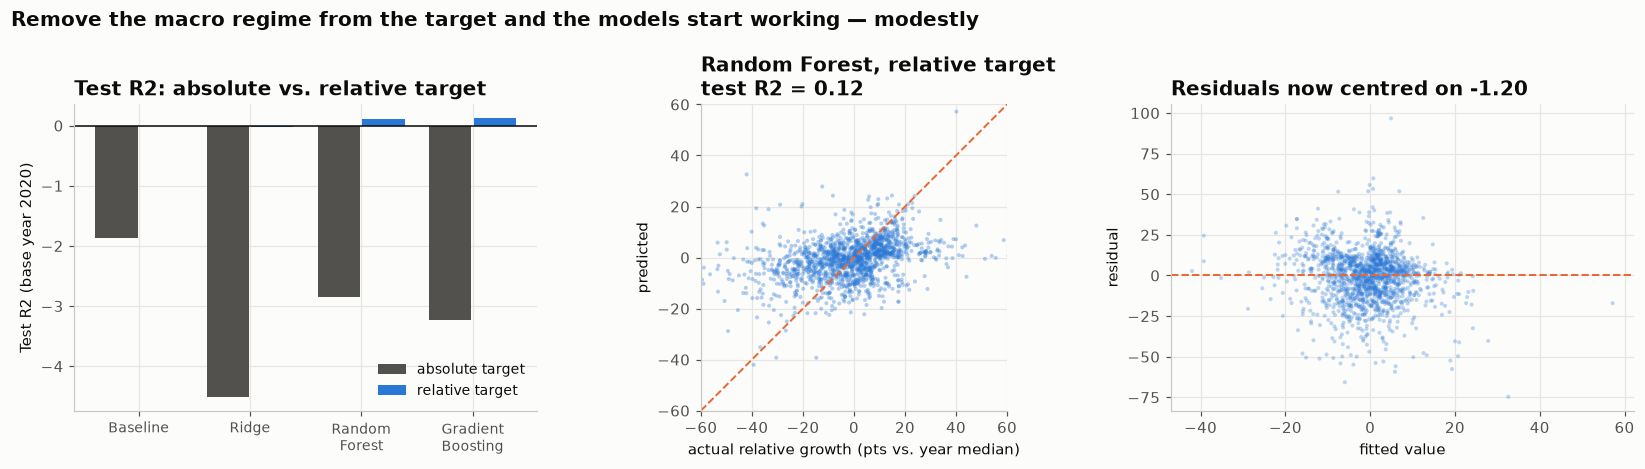

In [16]:
# ---- Figure 6: what removing the regime level does ----------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

ax = axes[0]
labels = ["Baseline", "Ridge", "Random\nForest", "Gradient\nBoosting"]
x = np.arange(4)
ax.bar(x - 0.2, results["Test R2"], 0.38, color=GRAY, label="absolute target")
ax.bar(x + 0.2, results_rel["Test R2"], 0.38, color=BLUE, label="relative target")
ax.axhline(0, color="#0b0b0b", lw=1)
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel("Test R2 (base year 2020)")
ax.set_title("Test R2: absolute vs. relative target")
ax.legend(fontsize=9)

ax = axes[1]
p = preds_rel["Random Forest"]["test"]
ax.scatter(test_r["rel_growth"], p, s=7, alpha=0.35, color=BLUE, edgecolor="none")
lo, hi = -60, 60
ax.plot([lo, hi], [lo, hi], color=ACCENT, ls="--", lw=1.3)
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
ax.set_xlabel("actual relative growth (pts vs. year median)")
ax.set_ylabel("predicted")
ax.set_title(f"Random Forest, relative target\ntest R2 = {results_rel.loc['Random Forest','Test R2']:.2f}")

ax = axes[2]
res_rf = test_r["rel_growth"].to_numpy() - p
ax.scatter(p, res_rf, s=7, alpha=0.3, color=BLUE, edgecolor="none")
ax.axhline(0, color=ACCENT, ls="--", lw=1.3)
ax.set_xlabel("fitted value"); ax.set_ylabel("residual")
ax.set_title(f"Residuals now centred on {res_rf.mean():+.2f}")

fig.suptitle("Remove the macro regime from the target and the models start working — modestly",
             x=0.005, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "fig06_relative_target")
plt.show()

**Figure 6.** The right-hand panel is the contrast with Figure 3 that makes the diagnosis conclusive.
There, residuals were a well-shaped band centred **23–37 points below zero**. Here, on the same ZIP codes
in the same test year with the same features, they are a well-shaped band centred on **−1.2** — nothing,
against a residual spread of roughly ±50. Only the target's definition changed. **The failure lived in
the level, not in the features.**

The middle panel is worth reading for a second thing. The predictions span roughly **−20 to +20** while
the actuals span **−60 to +60**: the model shrinks hard toward the mean. That is the correct behaviour
for a weak signal — an R² of 0.12 *should* produce cautious predictions — but it means the forecast in
Section 8 will understate the true spread between ZIP codes, not just its level.

---
# 6. Primary vs. secondary predictors

**A single Random Forest importance chart is not evidence.** Impurity-based importance is biased toward
high-cardinality continuous features — it rewards a feature for offering many possible split points,
whether or not those splits generalise. Every feature in this panel is continuous, and several are
near-duplicates of each other, so the bias has plenty of room to operate.

Three methods are therefore cross-checked:

| Method | What it measures | Blind spot |
|---|---|---|
| **Ridge standardized coefficients** | Direction (+/−) and magnitude in a linear fit | Splits credit arbitrarily among collinear features |
| **Permutation importance on the test set** | Actual out-of-sample predictive contribution | Understates any feature whose information a correlated twin can supply |
| **Grouped permutation importance** | Contribution of a whole correlated block | Cannot rank features inside a block |

The third is not optional here. D1 measured income ↔ rent at **+0.84**; permuting one of a correlated
pair leaves the other free to carry the same information, so both look unimportant and the block's real
contribution vanishes from the chart. Permuting the **block** fixes this.

Importances are computed on the **relative-target, rate-free** models, for the reason Section 5.1
established: on the absolute target, the level error swamps every feature effect, and importance
measured through a 23-point bias measures the bias.

In [17]:
# --- Method 1: Ridge standardized coefficients ---------------------------------------------------
ridge_rel = fitted_rel["Ridge"]
coefs = pd.Series(ridge_rel.named_steps["model"].coef_, index=NO_RATE)

# --- Method 2: per-feature permutation importance on the untouched test year ---------------------
def perm_imp(model, X, y, n_repeats=20):
    pi = permutation_importance(model, X, y, n_repeats=n_repeats,
                                random_state=RANDOM_STATE,
                                scoring="neg_root_mean_squared_error")
    return pd.Series(pi.importances_mean, index=X.columns)

perm_ridge = perm_imp(ridge_rel, test_r[NO_RATE], test_r["rel_growth"])
perm_rf    = perm_imp(fitted_rel["Random Forest"], test_r[NO_RATE], test_r["rel_growth"])
imp_rf     = pd.Series(fitted_rel["Random Forest"].feature_importances_, index=NO_RATE)

imp_tbl = pd.DataFrame({
    "Ridge coef (std)": coefs,
    "Ridge |coef| rank": coefs.abs().rank(ascending=False).astype(int),
    "Perm imp (RF, test)": perm_rf,
    "Perm rank (RF)": perm_rf.rank(ascending=False).astype(int),
    "RF impurity imp": imp_rf,
    "Impurity rank": imp_rf.rank(ascending=False).astype(int),
}).sort_values("Ridge coef (std)", key=abs, ascending=False)
imp_tbl.round(3)

,Ridge coef (std),Ridge |coef| rank,"Perm imp (RF, test)",Perm rank (RF),RF impurity imp,Impurity rank
mortgage_to_income_ratio,-2.573,1,-0.004,11,0.065,6
price_to_income_ratio,-2.241,2,0.006,10,0.056,9
price_to_rent_ratio,-2.157,3,0.145,7,0.167,1
home_value_1yr_growth_pct,1.730,4,0.200,4,0.062,7
bachelor_degree_pct,-1.723,5,0.178,5,0.084,5
population,1.660,6,2.070,1,0.099,3
unemployment_rate,1.634,7,-0.095,12,0.056,8
home_value_3yr_growth_pct,-1.455,8,0.163,6,0.087,4
rent_to_income_ratio,1.318,9,0.008,9,0.045,13
current_home_value,1.253,10,-0.202,13,0.132,2


**The three columns disagree, and the disagreement is the finding.**

`mortgage_to_income_ratio` has the **largest** Ridge coefficient of all 13 features (−2.573) and ranks
**11th of 13** on permutation importance, at **−0.004** — shuffling it changes test RMSE by nothing at
all. `price_to_income_ratio` is coefficient rank 2 and permutation rank 10. Taken at face value that
says the affordability features are worthless.

Taken correctly, it says permutation importance cannot see through collinearity. Section 1.2 established
that `mortgage_to_income_ratio` is a within-year rescaling of `price_to_income_ratio` — they are
**perfectly rank-correlated inside any test year**. Shuffling one leaves the other carrying the identical
information, so each individually looks free to destroy. `price_to_rent_ratio` is a third measurement of
the same quantity.

The same trap runs the other way for `current_home_value`: coefficient rank 10, permutation rank 13, at
**−0.202**. And the impurity column crowns `price_to_rent_ratio` (rank 1) — a fourth answer.

The grouped permutation resolves all of it.

In [18]:
# --- Method 3: grouped permutation importance ----------------------------------------------------
BLOCKS = {
    "Affordability": ["price_to_income_ratio", "price_to_rent_ratio",
                      "mortgage_to_income_ratio", "rent_to_income_ratio"],
    "Affluence level": ["current_home_value", "median_household_income",
                        "median_gross_rent", "bachelor_degree_pct"],
    "Urban scale": ["population", "population_growth_pct"],
    "Momentum": ["home_value_1yr_growth_pct", "home_value_3yr_growth_pct"],
    "Labor market": ["unemployment_rate"],
}
assert sorted(c for cols in BLOCKS.values() for c in cols) == sorted(NO_RATE)


def grouped_perm(model, X, y, blocks, n_repeats=20):
    """Permute a whole correlated block at once, so a feature's twin cannot cover for it."""
    base = np.sqrt(mean_squared_error(y, model.predict(X)))
    out = {}
    for name, cols in blocks.items():
        deltas = []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[cols] = Xp[cols].to_numpy()[rng.permutation(len(Xp))]   # keep within-block structure
            deltas.append(np.sqrt(mean_squared_error(y, model.predict(Xp))) - base)
        out[name] = float(np.mean(deltas))
    return pd.Series(out)

grouped = pd.DataFrame({
    "Ridge (val 2019)": grouped_perm(ridge_rel, val_r[NO_RATE], val_r["rel_growth"], BLOCKS),
    "Ridge (test 2020)": grouped_perm(ridge_rel, test_r[NO_RATE], test_r["rel_growth"], BLOCKS),
    "RF (val 2019)": grouped_perm(fitted_rel["Random Forest"], val_r[NO_RATE], val_r["rel_growth"], BLOCKS),
    "RF (test 2020)": grouped_perm(fitted_rel["Random Forest"], test_r[NO_RATE], test_r["rel_growth"], BLOCKS),
})
grouped["mean"] = grouped.mean(axis=1)
grouped.sort_values("mean", ascending=False).round(3)

,Ridge (val 2019),Ridge (test 2020),RF (val 2019),RF (test 2020),mean
Urban scale,0.525,0.513,2.751,2.373,1.541
Affordability,1.477,0.816,2.700,0.855,1.462
Affluence level,-0.238,-0.314,1.124,0.274,0.211
Momentum,-0.315,0.179,0.400,0.103,0.092
Labor market,-0.142,-0.194,0.175,-0.083,-0.061


**With the block permuted as a unit, affordability is the strongest or second-strongest block in every
model and in both held-out years** — the exact opposite of what the per-feature chart implied. The
per-feature near-zeros were a collinearity artifact.

| Block | Ridge val 2019 | Ridge test 2020 | RF val 2019 | RF test 2020 | mean |
|---|---|---|---|---|---|
| **Urban scale** | 0.525 | 0.513 | **2.751** | **2.373** | **1.541** |
| **Affordability** | **1.477** | **0.816** | 2.700 | 0.855 | **1.462** |
| Affluence level | −0.238 | −0.314 | 1.124 | 0.274 | 0.211 |
| Momentum | −0.315 | 0.179 | 0.400 | 0.103 | 0.092 |
| Labor market | −0.142 | −0.194 | 0.175 | −0.083 | −0.061 |

Two blocks separate cleanly from the rest and are effectively tied on the mean: **urban scale** (which
Random Forest ranks first in both years) and **affordability** (which Ridge ranks first in both years).
Every other block is near zero or negative.

In [19]:
# --- Sign stability across base years: does the association hold, or flip? -----------------------
stability = pd.DataFrame({
    str(y): [g[c].corr(g["rel_growth"]) for c in NO_RATE]
    for y, g in panel.groupby("base_year")
}, index=NO_RATE)
stability["sign consistent"] = np.where(
    (stability > 0).all(axis=1) | (stability < 0).all(axis=1), "yes", "FLIPS")
stability.round(3)

,2016,2017,2018,2019,2020,sign consistent
current_home_value,-0.317,-0.303,-0.322,-0.117,0.027,FLIPS
home_value_1yr_growth_pct,0.139,0.409,-0.116,-0.001,0.304,FLIPS
home_value_3yr_growth_pct,-0.032,0.091,0.081,0.123,0.085,FLIPS
median_household_income,-0.259,-0.208,-0.143,0.065,0.162,FLIPS
median_gross_rent,-0.223,-0.198,-0.128,0.113,0.186,FLIPS
population,0.054,0.124,0.161,0.279,0.285,yes
population_growth_pct,-0.037,-0.017,-0.051,-0.024,-0.030,yes
unemployment_rate,0.278,0.212,0.117,0.002,-0.059,FLIPS
bachelor_degree_pct,-0.343,-0.328,-0.287,-0.085,0.024,FLIPS
price_to_income_ratio,-0.328,-0.322,-0.413,-0.288,-0.193,yes


**This table is the tie-breaker, and it demotes several features that the coefficient chart flattered.**

Reading the 2016 and 2020 columns against each other:

| Feature | 2016 | 2020 |
|---|---|---|
| `current_home_value` | −0.317 | **+0.027** |
| `bachelor_degree_pct` | −0.343 | **+0.024** |
| `median_household_income` | −0.259 | **+0.162** |
| `median_gross_rent` | −0.223 | **+0.186** |
| `unemployment_rate` | +0.278 | **−0.059** |

The "cheap, less-educated, economically slack markets catch up" pattern that dominated 2016–2018 **is
not present in 2020 at all** — every one of those five features has reversed. A predictor whose sign is
not stable across the panel cannot be called primary, whatever its coefficient says.

`home_value_1yr_growth_pct` fails the test differently: it does not drift, it oscillates
(**+0.139, +0.409, −0.116, −0.001, +0.304**). Momentum was the single strongest correlate in 2017 and in
2020, and had the *wrong* sign in 2018.

Only four features hold their sign across all five base years: the three affordability ratios (negative
throughout, attenuating from about −0.33 to −0.19 but never flipping) and `population` (positive
throughout, and *strengthening*: +0.054 → +0.285). `population_growth_pct` is technically
sign-consistent, but at −0.017 to −0.051 it is consistently nothing.

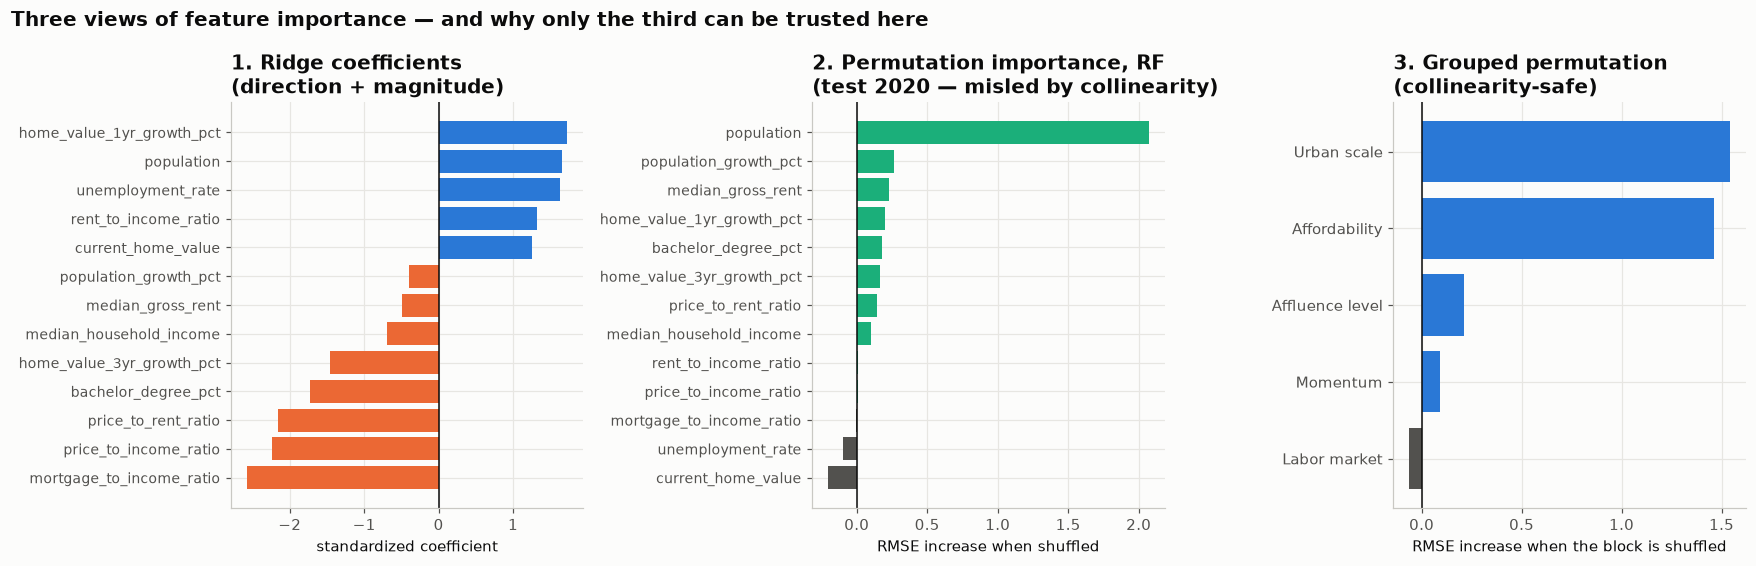

In [20]:
# ---- Figure 7: the three importance views ------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))

ax = axes[0]
c = coefs.sort_values()
ax.barh(range(len(c)), c.values, color=[ACCENT if v < 0 else BLUE for v in c.values])
ax.set_yticks(range(len(c))); ax.set_yticklabels(c.index, fontsize=9)
ax.axvline(0, color="#0b0b0b", lw=1)
ax.set_xlabel("standardized coefficient")
ax.set_title("1. Ridge coefficients\n(direction + magnitude)")

ax = axes[1]
p = perm_rf.sort_values()
ax.barh(range(len(p)), p.values, color=[GRAY if v < 0 else GREEN for v in p.values])
ax.set_yticks(range(len(p))); ax.set_yticklabels(p.index, fontsize=9)
ax.axvline(0, color="#0b0b0b", lw=1)
ax.set_xlabel("RMSE increase when shuffled")
ax.set_title("2. Permutation importance, RF\n(test 2020 — misled by collinearity)")

ax = axes[2]
g = grouped["mean"].sort_values()
ax.barh(range(len(g)), g.values, color=[GRAY if v < 0 else BLUE for v in g.values])
ax.set_yticks(range(len(g))); ax.set_yticklabels(g.index, fontsize=10)
ax.axvline(0, color="#0b0b0b", lw=1)
ax.set_xlabel("RMSE increase when the block is shuffled")
ax.set_title("3. Grouped permutation\n(collinearity-safe)")

fig.suptitle("Three views of feature importance — and why only the third can be trusted here",
             x=0.005, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "fig07_feature_importance")
plt.show()

## 6.1 The classification

A feature is **primary** only if it ranks high in *both* independent methods **and** keeps a consistent
sign across every base year.

### Primary

| Feature / block | Ridge coef | Grouped perm (mean) | Sign across 5 base years |
|---|---|---|---|
| **`population`** | +1.66 | Urban scale: **1.541** | **Positive in all 5**, strengthening (+0.054 → +0.285) |
| **`price_to_income_ratio`** | −2.24 | Affordability: **1.462** | **Negative in all 5** |
| **`price_to_rent_ratio`** | −2.16 | " | **Negative in all 5** |
| **`mortgage_to_income_ratio`** | **−2.57** (largest) | " | **Negative in all 5** |

Two blocks, effectively tied, and each is ranked first by one of the two model families.

**The affordability block** is the one the project set out to test, and it holds: *ZIP codes where the
cost of buying already consumes a large share of local income subsequently grew more slowly than their
year's median.* Associated with, not causing — the mechanism is not identified here, and a plausible
alternative reading is simply that expensive markets had less headroom.

One honest qualification, from Section 1.2: the three affordability features are **not three independent
pieces of evidence**. `mortgage_to_income_ratio` is a within-year rescaling of `price_to_income_ratio`,
so those two are the same cross-sectional signal twice. D2's engineered feature earns the largest
coefficient in the model, but it did not add information D1 lacked. `price_to_rent_ratio` is the one
genuinely distinct member of the block.

**`population` is the other primary predictor**, ranked **first** by Random Forest permutation
importance in both held-out years and the only feature whose association *grows* across the panel.
Larger, denser ZIP codes outperformed. Note that `population_growth_pct` remains the true null D1 found
(−0.017 to −0.051 in every year): urban **scale** carries signal; urban **change** does not.

### Secondary

| Feature | Why only secondary |
|---|---|
| `home_value_1yr_growth_pct` | Ridge coefficient rank 4 and permutation rank 4 — but its sign **oscillates** (+0.139, +0.409, −0.116, −0.001, +0.304). Strongest single correlate in 2017 *and* 2020, wrong-signed in 2018. Real, and not dependable |
| `current_home_value`, `bachelor_degree_pct`, `median_household_income`, `median_gross_rent` | Large Ridge coefficients, but every one **flips sign** between 2016 and 2020. They describe the 2016–2018 catch-up regime, which did not repeat. As a block, "Affluence level" scores 0.211 — well behind the top two |
| `home_value_3yr_growth_pct` | Weak throughout (−0.032 to +0.123), consistent with D1's finding that momentum is nearly useless at this horizon |

### Weak

`unemployment_rate` (sign flips +0.278 → −0.059; the sole member of a block with a **negative** mean
grouped importance), `population_growth_pct` (a true null in D1 and here), `rent_to_income_ratio` (sign
flips, and its within-year correlations hover near zero).

### `mortgage_rate` — the feature that must be read carefully

D1's §6.2 warning is confirmed empirically. `mortgage_rate` is constant within a base year, so **inside
a single-year test set it cannot distinguish one ZIP code from another**. Measured directly:

In [21]:
# mortgage_rate is a constant within any single base year -- so within the test year it can carry
# exactly zero ranking information, no matter what an importance chart trained on 5 years suggests.
print(f"distinct mortgage_rate values in the test year: {test['mortgage_rate'].nunique()}")

pi_rate = permutation_importance(
    fitted["Random Forest"], X_test, y_test, n_repeats=20,
    random_state=RANDOM_STATE, scoring="neg_root_mean_squared_error")
rate_perm = pd.Series(pi_rate.importances_mean, index=FEATURES)["mortgage_rate"]
rate_impurity = pd.Series(fitted["Random Forest"].feature_importances_, index=FEATURES)

print(f"permutation importance of mortgage_rate on the test set: {rate_perm:.6f}")
print(f"RF *impurity* importance of mortgage_rate:                {rate_impurity['mortgage_rate']:.3f}"
      f"   (rank {int(rate_impurity.rank(ascending=False)['mortgage_rate'])} of {len(FEATURES)})")
print(f"RF *impurity* importance of estimated_monthly_mortgage:   "
      f"{rate_impurity['estimated_monthly_mortgage']:.3f}"
      f"   (rank {int(rate_impurity.rank(ascending=False)['estimated_monthly_mortgage'])} of {len(FEATURES)})")

distinct mortgage_rate values in the test year: 1


permutation importance of mortgage_rate on the test set: 0.000000
RF *impurity* importance of mortgage_rate:                0.140   (rank 2 of 15)
RF *impurity* importance of estimated_monthly_mortgage:   0.141   (rank 1 of 15)


> **`mortgage_rate` has an impurity importance of 0.140 — rank 2 of 15 — and a permutation importance
> on the test set of exactly 0.000000.**

That contrast is the cleanest possible demonstration of why impurity importance must not be trusted
alone. The Random Forest split on `mortgage_rate` constantly, because within the pooled training data
it is a perfect proxy for base year and base year explains the growth level beautifully. Shuffling it
inside the test year changes **nothing**, because there is only one value to shuffle.

Any importance `mortgage_rate` displays reflects **between-year** variation, never **between-ZIP**
variation. It is a market-cycle control. Section 5.2 already showed it is worse than useless
out-of-time, and Section 8 shows it is a hazard in the forecast.

---
# 7. Listings ablation — do for-sale listings features help?

Zillow's listings series begins **2018-03**, so it cannot join base years 2016–2017. Rather than shrink
the panel from 7,487 rows to 4,539, this runs as a **contained experiment** on the 2018–2020 subset.

## 7.1 The selection-bias trap — read this before the results

Listings coverage is **not missing at random**, and the bias points straight at the outcome.

In [22]:
sub = panel[panel["base_year"].isin([2018, 2019, 2020])].copy()
FOUR = ["inventory_per_1k_housing_units", "new_listings_per_1k_housing_units",
        "price_cut_pct", "list_to_value_ratio"]

sub["has_all_four"] = sub[FOUR].notna().all(axis=1)
sub["has_inventory"] = sub["inventory_per_1k_housing_units"].notna()

print(f"2018-2020 subset: {len(sub):,} rows")
for col, label in [("has_inventory", "inventory only"), ("has_all_four", "all four features")]:
    n = int(sub[col].sum())
    print(f"  {label:<20} {n:>5,} rows  ({n/len(sub):5.1%} coverage)")

print("\nWho gets listings coverage? (medians)")
bias_tbl = pd.concat([
    sub.groupby("has_all_four").agg(
        n=("zip_code", "size"), median_population=("population", "median"),
        median_5yr_growth=(TARGET, "median")).rename(index={False: "no", True: "yes"}).assign(subset="all four"),
    sub.groupby("has_inventory").agg(
        n=("zip_code", "size"), median_population=("population", "median"),
        median_5yr_growth=(TARGET, "median")).rename(index={False: "no", True: "yes"}).assign(subset="inventory"),
]).set_index("subset", append=True).swaplevel()
bias_tbl.round(1)

2018-2020 subset: 4,539 rows
  inventory only       3,403 rows  (75.0% coverage)
  all four features    1,583 rows  (34.9% coverage)

Who gets listings coverage? (medians)


n  median_population  median_5yr_growth
subset                                                   
all four  no   2956          9,953.500             30.600
          yes  1583         41,412.000             40.600
inventory no   1136          1,529.500             26.600
          yes  3403         31,455.000             37.300

**Zillow publishes listings data for large, active markets — and those markets grew faster.**

| Has all four listings features | ZIPs | Median population | Median 5-yr growth |
|---|---|---|---|
| No | 2,956 | 9,954 | 30.6% |
| **Yes** | **1,583** | **41,412** | **40.6%** |

Coverage brings **4.2× the population** and **+10 points of growth**. Coverage therefore correlates with
both market size *and the target*. Two consequences follow, and both are binding:

1. **A complete-case analysis on all four features keeps only 1,583 of 4,539 rows (34.9%)**, systematically
   larger and faster-growing than California as a whole. Any conclusion drawn from that subset is
   **silently conditional on big-city markets** and does not generalize.
2. **A listings-availability flag must never be used as a predictor.** It would look highly informative —
   coverage predicts growth at +10 points — but it measures **Zillow's reporting behaviour**, not the
   housing market. It is **leakage by proxy**. `population` is the correct substitute: it captures the
   real underlying urban-scale effect and is available for every row. (`population` is already in
   `FEATURES`, and Section 6 found it *primary*, which is consistent with the +10-point gap being an
   urban-scale effect rather than a listings effect.)

## 7.2 Experiment design

**Primary — inventory only.** `for_sale_inventory` reaches **75.0% coverage (3,403 rows)** and is far
less biased than the four-feature intersection (median population 31,455 vs. 41,412).

- **Model A:** core features (rate features excluded, per Section 5.2)
- **Model B:** core + `inventory_per_1k_housing_units`

Fit on **identical rows** — those with inventory present — with the same folds. Only a same-rows
comparison isolates the effect of the **feature** rather than the effect of the **sample**.

Validation is **leave-one-base-year-out `GroupKFold`, 3 folds**, over 2018/2019/2020. There is no
separate holdout: with three base years, each year serves as the test fold once.

**Secondary — all four features**, complete-case on 1,583 rows, reported with the bias caveat stated
above. A robustness check, not a headline.

**Hypothesis stated up front:** inventory and price cuts are strong **short-run** indicators, but their
signal should decay over a five-year horizon. Confirming *or* refuting that is a genuine finding.

In [23]:
def loyo(d, feats, target):
    """Leave-one-base-year-out CV. Identical rows, identical folds, only the feature list changes."""
    gkf = GroupKFold(n_splits=3)
    X, y, g = d[feats], d[target], d["base_year"]
    out = {}
    for name, model in {
        "Ridge": Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=100.0))]),
        "Random Forest": RandomForestRegressor(
            n_estimators=400, min_samples_leaf=5, max_features=0.5,
            random_state=RANDOM_STATE, n_jobs=-1),
    }.items():
        p = cross_val_predict(model, X, y, cv=gkf, groups=g)
        out[name] = {"RMSE": np.sqrt(mean_squared_error(y, p)),
                     "MAE": mean_absolute_error(y, p), "R2": r2_score(y, p)}
    return out


def ablate(d, extra, target, label):
    A, B = loyo(d, NO_RATE, target), loyo(d, NO_RATE + extra, target)
    return pd.DataFrame([{
        "experiment": label, "n": len(d), "model": m,
        "A core RMSE": A[m]["RMSE"], "B +listings RMSE": B[m]["RMSE"],
        "delta RMSE": B[m]["RMSE"] - A[m]["RMSE"],
        "A core R2": A[m]["R2"], "B +listings R2": B[m]["R2"],
    } for m in A])


inv_rows = sub[sub["has_inventory"]].copy()
cc_rows  = sub[sub["has_all_four"]].copy()

ablation = pd.concat([
    ablate(inv_rows, ["inventory_per_1k_housing_units"], TARGET, "PRIMARY inventory, absolute"),
    ablate(inv_rows, ["inventory_per_1k_housing_units"], "rel_growth", "PRIMARY inventory, relative"),
    ablate(cc_rows,  FOUR, TARGET, "SECONDARY all four, absolute"),
    ablate(cc_rows,  FOUR, "rel_growth", "SECONDARY all four, relative"),
], ignore_index=True)
ablation.set_index(["experiment", "model"]).round(3)

n  A core RMSE  B +listings RMSE  delta RMSE  A core R2  B +listings R2
experiment                   model                                                                                    
PRIMARY inventory, absolute  Ridge          3403       17.890            17.421      -0.470      0.039           0.089
                             Random Forest  3403       17.140            16.816      -0.324      0.118           0.151
PRIMARY inventory, relative  Ridge          3403       15.816            15.824       0.008      0.147           0.146
                             Random Forest  3403       14.714            14.300      -0.414      0.262           0.303
SECONDARY all four, absolute Ridge          1583       16.776            15.375      -1.401     -0.132           0.049
                             Random Forest  1583       14.559            15.377       0.817      0.147           0.049
SECONDARY all four, relative Ridge          1583       13.553            13.212      -0.340      0.091           0.136
                             Random Forest  1583       11.663            11.149      -0.513      0.327           0.385

## 7.3 Results

**Primary experiment — `inventory_per_1k_housing_units`, 3,403 identical rows:**

| Model | A: core RMSE | B: + inventory | Δ RMSE | A R² | B R² |
|---|---|---|---|---|---|
| Ridge | 17.89 | **17.42** | **−0.47** | +0.039 | +0.089 |
| Random Forest | 17.14 | **16.82** | **−0.32** | +0.118 | +0.151 |

**Inventory helps, consistently and modestly.** RMSE falls for both model families, and R² rises by
about 3–5 points. On the relative target the Random Forest gain is similar (−0.41 RMSE,
R² +0.262 → +0.303); Ridge sees essentially nothing (+0.008), which says the inventory signal is
**nonlinear** — a threshold effect that a linear term cannot express.

A 0.3–0.5 point RMSE improvement on a ~17-point error is a **~2–3% error reduction**. Real, replicated
across model families and across both target definitions, and small.

**Secondary experiment — all four features, 1,583 complete cases:**

| Model | A: core RMSE | B: + 4 features | Δ RMSE |
|---|---|---|---|
| Ridge | 16.78 | **15.38** | **−1.40** |
| Random Forest | 14.56 | 15.38 | **+0.82** |

The two model families **disagree in sign**. Ridge improves substantially; Random Forest gets *worse*.
On a 1,583-row sample with a 15-feature core, adding four more correlated features is enough to cost
the forest more in variance than the features return in signal. On the relative target both improve
(Ridge −0.34, RF −0.51), which suggests the absolute-target disagreement is partly the same level
problem from Section 5.

**This result is conditional on big-city markets** — 1,583 rows with 4.2× the state's median ZIP
population — and should not be generalized to California as a whole. It is reported because omitting it
would be selective; it is not a headline.

In [24]:
# Which listings feature carries signal, and does it survive the regime demeaning?
sig = []
for c in FOUR:
    d = sub.dropna(subset=[c])
    sig.append({"feature": c, "n": len(d), "coverage": len(d) / len(sub),
                "r with 5-yr growth": d[c].corr(d[TARGET]),
                "r with relative growth": d[c].corr(d["rel_growth"])})
pd.DataFrame(sig).set_index("feature").round(3)

,n,coverage,r with 5-yr growth,r with relative growth
feature,,,,
inventory_per_1k_housing_units,3403,0.750,0.154,0.092
new_listings_per_1k_housing_units,1734,0.382,0.145,0.233
price_cut_pct,2014,0.444,0.260,0.049
list_to_value_ratio,1994,0.439,0.152,0.143


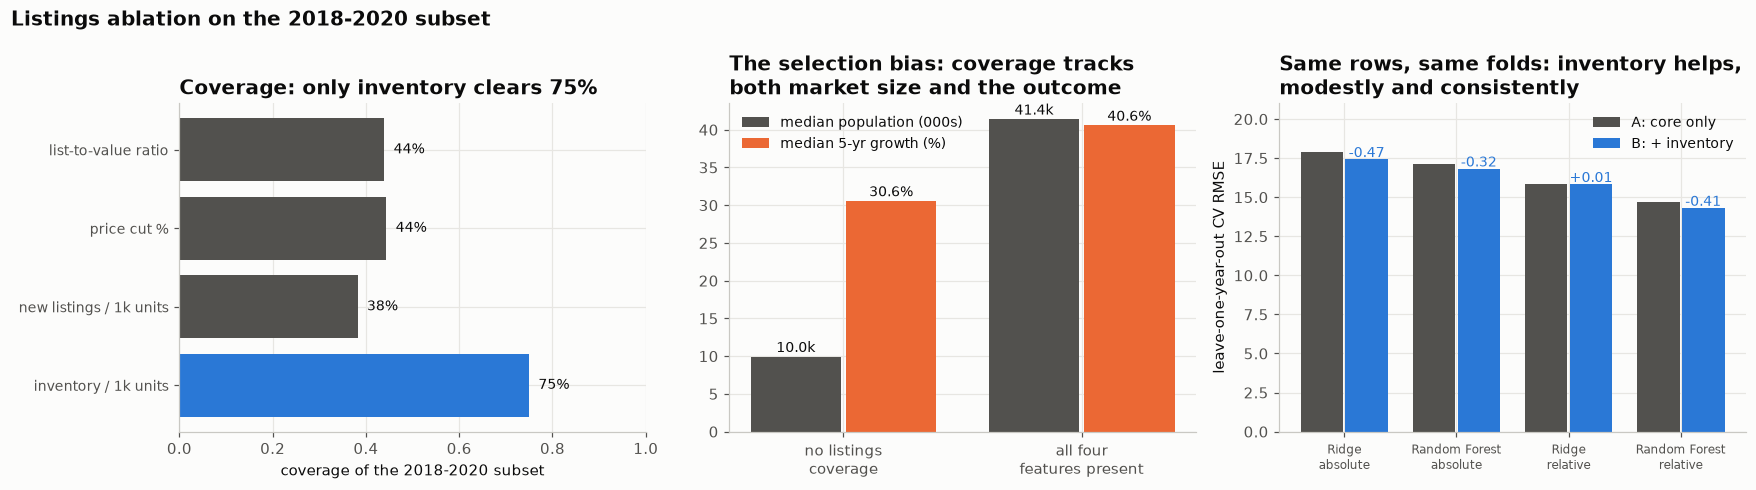

In [25]:
# ---- Figure 8: listings ablation ----------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

ax = axes[0]
SHORT = {"inventory_per_1k_housing_units": "inventory / 1k units",
         "new_listings_per_1k_housing_units": "new listings / 1k units",
         "price_cut_pct": "price cut %", "list_to_value_ratio": "list-to-value ratio"}
cov = [sub[c].notna().mean() for c in FOUR]
ax.barh(range(4), cov, color=[BLUE if v > 0.5 else GRAY for v in cov])
ax.set_yticks(range(4)); ax.set_yticklabels([SHORT[c] for c in FOUR], fontsize=9)
ax.set_xlim(0, 1); ax.set_xlabel("coverage of the 2018-2020 subset")
for i, v in enumerate(cov):
    ax.text(v + 0.02, i, f"{v:.0%}", va="center", fontsize=9)
ax.set_title("Coverage: only inventory clears 75%")

ax = axes[1]
grp = sub.groupby("has_all_four").agg(pop=("population", "median"), g=(TARGET, "median"))
x = np.arange(2)
ax.bar(x - 0.2, grp["pop"] / 1000, 0.38, color=GRAY, label="median population (000s)")
ax.bar(x + 0.2, grp["g"], 0.38, color=ACCENT, label="median 5-yr growth (%)")
ax.set_xticks(x); ax.set_xticklabels(["no listings\ncoverage", "all four\nfeatures present"])
for i, (a, b) in enumerate(zip(grp["pop"] / 1000, grp["g"])):
    ax.text(i - 0.2, a + 0.6, f"{a:.1f}k", ha="center", fontsize=9)
    ax.text(i + 0.2, b + 0.6, f"{b:.1f}%", ha="center", fontsize=9)
ax.legend(fontsize=9)
ax.set_title("The selection bias: coverage tracks\nboth market size and the outcome")

ax = axes[2]
prim = ablation[ablation["experiment"].str.startswith("PRIMARY")]
lab = [f"{m}\n{e.split(', ')[1]}" for e, m in zip(prim["experiment"], prim["model"])]
x = np.arange(len(prim))
ax.bar(x - 0.2, prim["A core RMSE"], 0.38, color=GRAY, label="A: core only")
ax.bar(x + 0.2, prim["B +listings RMSE"], 0.38, color=BLUE, label="B: + inventory")
for i, (a, b) in enumerate(zip(prim["A core RMSE"], prim["B +listings RMSE"])):
    ax.text(i + 0.2, b + 0.15, f"{b - a:+.2f}", ha="center", fontsize=9, color=BLUE)
ax.set_xticks(x); ax.set_xticklabels(lab, fontsize=8)
ax.set_ylabel("leave-one-year-out CV RMSE")
ax.set_ylim(0, 21)
ax.legend(fontsize=9)
ax.set_title("Same rows, same folds: inventory helps,\nmodestly and consistently")

fig.suptitle("Listings ablation on the 2018-2020 subset", x=0.005, ha="left",
             fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "fig08_listings_ablation")
plt.show()

## 7.4 The verdict on listings

**The hypothesis was half right.**

`price_cut_pct` has the strongest raw correlation with five-year growth of the four (**+0.260**) — and
it **collapses to +0.049 against relative growth**. Nearly all of its apparent signal was telling us
*which base year the row came from*, not which ZIP code it was: price cuts were common in the
higher-rate 2018 market and rare in the 2020 market, and 2018 and 2020 had very different subsequent
growth. That is the year effect wearing a feature's clothing.

`new_listings_per_1k_housing_units` behaves the opposite way — **+0.145 raw, rising to +0.233 against
relative growth** — but reaches only **38% coverage**, the most biased sample of the four.

**Overall:** for-sale inventory carries a real but small five-year signal, worth roughly a 2–3% error
reduction, and it is **nonlinear** (Random Forest captures it; Ridge barely does). The short-run
liquidity indicators — price cuts especially — **do not survive the five-year horizon** once the
base-year effect is removed. Given that the price of using all four features is a 65% loss of sample and
a systematic tilt toward big cities, **the primary models correctly exclude them.**

---
# 8. The 2029 forecast

The panel stops at base year 2020 because a row only exists where the realized outcome is already
observable. To forecast 2029, the identical feature block is rebuilt for base year **2024**
(Dec-2024 ZHVI + ACS 2024 + the 2024 mean mortgage rate) by `scripts/build_forecast_frame.py`, using
the same anchors and formulas as D1. That frame has **no target column** — Dec-2029 has not happened.

$$ \text{predicted value}_{2029} = \text{home value}_{2024} \times
   \left(1 + \frac{\text{predicted 5-yr growth}}{100}\right) $$

## 8.1 Read this before the numbers

Four caveats. None is boilerplate; each changes how the forecast must be read.

1. **The 2024 mortgage rate (6.72%) is entirely outside the training range (3.11–4.55%).** Not near the
   edge — 48% above the maximum ever seen.
2. **Random Forests cannot extrapolate.** They partition the training space; a value beyond the last
   split boundary receives the same prediction as a value *at* the boundary. Presented with 6.72%, the
   forest silently answers as though it were 4.55%.
3. **Ridge extrapolates, and that is worse.** It will project a straight line 48% past the data.
4. **All five training windows contain the pandemic housing boom.** The model has only ever seen "what
   predicted growth during a boom," and the mean it regresses toward is a boom-era mean. No amount of
   cross-validation repairs this.

The forecast is therefore produced **twice — with and without the rate features — and the gap is
reported.**

In [26]:
forecast = engineer(pd.read_csv(PROC / "ca_zip_forecast_frame_2024.csv", dtype={"zip_code": str}))
print(f"forecast frame: {len(forecast):,} California ZIP codes, base year 2024")

print("\nHow far outside the training range is 2024?")
cov = []
for c in ["mortgage_rate", "current_home_value", "mortgage_to_income_ratio",
          "price_to_income_ratio", "price_to_rent_ratio"]:
    cov.append({"feature": c, "train min": panel[c].min(), "train max": panel[c].max(),
                "2024 median": forecast[c].median(),
                "% of 2024 rows above train max": (forecast[c] > panel[c].max()).mean() * 100})
pd.DataFrame(cov).set_index("feature").round(3)

forecast frame: 1,543 California ZIP codes, base year 2024

How far outside the training range is 2024?


,train min,train max,2024 median,% of 2024 rows above train max
feature,,,,
mortgage_rate,3.112,4.545,6.721,100.000
current_home_value,"45,530.059","6,483,301.321","723,096.226",0.065
mortgage_to_income_ratio,0.052,3.749,0.467,0.065
price_to_income_ratio,1.185,81.893,7.526,0.065
price_to_rent_ratio,4.056,296.643,31.177,0.000


`mortgage_rate` is the only feature genuinely out of range, and it is **100% out of range** — every one
of the 1,543 ZIP codes carries 6.72%. The affordability ratios stay almost entirely inside the training
envelope (0.06% of rows exceed the maximum `mortgage_to_income_ratio`), because the 2022–2024 price
correction partly offset the rate rise. That is reassuring for the primary predictor and damning for
the rate.

In [27]:
# Final models are refit on ALL five base years -- the forecast should use every observation available,
# and there is no held-out year left to protect once evaluation is finished.
def fit_final(feats):
    rf = RandomForestRegressor(n_estimators=400, min_samples_leaf=5, max_features=0.5,
                               random_state=RANDOM_STATE, n_jobs=-1).fit(panel[feats], panel[TARGET])
    rg = Pipeline([("scaler", StandardScaler()),
                   ("model", Ridge(alpha=1000.0))]).fit(panel[feats], panel[TARGET])
    return rf, rg

rf_rate, rg_rate = fit_final(FEATURES)
rf_norate, rg_norate = fit_final(NO_RATE)

fc_preds = {
    "Random Forest, with rate": rf_rate.predict(forecast[FEATURES]),
    "Random Forest, no rate":   rf_norate.predict(forecast[NO_RATE]),
    "Ridge, with rate":         rg_rate.predict(forecast[FEATURES]),
    "Ridge, no rate":           rg_norate.predict(forecast[NO_RATE]),
}
summary = pd.DataFrame({k: pd.Series(v).describe(percentiles=[.1, .5, .9])
                        for k, v in fc_preds.items()}).T
summary[["mean", "10%", "50%", "90%"]].round(2)

,mean,10%,50%,90%
"Random Forest, with rate",38.970,26.870,40.310,49.800
"Random Forest, no rate",38.570,23.680,39.520,51.340
"Ridge, with rate",57.520,49.880,57.870,64.760
"Ridge, no rate",37.450,29.480,37.890,45.060


## 8.2 The extrapolation gap — both failure modes on display

| Model | Mean predicted 2024→2029 growth |
|---|---|
| Random Forest, **with** rate | **38.97%** |
| Random Forest, **no** rate | **38.57%** |
| Ridge, **no** rate | 37.45% |
| Ridge, **with** rate | **57.52%** |

**The Random Forest gap is 0.40 percentage points.** Handed a mortgage rate 48% above anything in its
training data, the forest's forecast barely moves. That is not robustness — it is the clamping described
in caveat 2, made visible. The rate feature is *present* and doing *nothing*.

**Ridge's gap is +20.07 percentage points, and in the wrong direction.** Ridge predicts that a
**6.72%** mortgage rate implies **more** appreciation than a 3.9% one. Nothing in housing economics
supports that; it is the pooled correlation between the panel's five rate values and their five growth
levels (r = +0.158, which D1 identified as a base-year effect in disguise), projected linearly far
beyond the data.

> **Neither model can price the 2024 interest-rate environment.** One ignores it; the other reads it
> backwards. The **Random Forest without rate features** is used below — not because it handles the rate
> correctly, but because it is the only option that does not *pretend* to.

In [28]:
# ---- Prediction intervals from out-of-time residual spread --------------------------------------
# The honest uncertainty here is not the training-fold residual spread -- it is how wrong the model
# was the last time it was asked to predict a year it had never seen. That is the 2020 test set.
oot_resid = y_test.to_numpy() - preds_nr["Random Forest"]["test"]
q10, q50, q90 = np.percentile(oot_resid, [10, 50, 90])

print("Out-of-time residual distribution (base year 2020, RF without rate features)")
print(f"  mean {oot_resid.mean():+.2f}   sd {oot_resid.std():.2f}")
print(f"  10th pct {q10:+.2f}   median {q50:+.2f}   90th pct {q90:+.2f}  (percentage points)")

forecast["predicted_5yr_growth_pct"] = fc_preds["Random Forest, no rate"]
forecast["predicted_growth_lo"] = forecast["predicted_5yr_growth_pct"] + q10
forecast["predicted_growth_hi"] = forecast["predicted_5yr_growth_pct"] + q90

for col, g in [("predicted_home_value_2029", "predicted_5yr_growth_pct"),
               ("predicted_value_2029_lo", "predicted_growth_lo"),
               ("predicted_value_2029_hi", "predicted_growth_hi")]:
    forecast[col] = forecast["current_home_value"] * (1 + forecast[g] / 100)

print(f"\nPoint forecast   median 2024 value ${forecast['current_home_value'].median():,.0f}"
      f"  ->  2029 ${forecast['predicted_home_value_2029'].median():,.0f}"
      f"   ({forecast['predicted_5yr_growth_pct'].median():.1f}%)")
print(f"80% interval     ${forecast['predicted_value_2029_lo'].median():,.0f}"
      f"  to  ${forecast['predicted_value_2029_hi'].median():,.0f}"
      f"   ({forecast['predicted_growth_lo'].median():.1f}% to {forecast['predicted_growth_hi'].median():.1f}%)")

Out-of-time residual distribution (base year 2020, RF without rate features)
  mean -23.10   sd 16.75
  10th pct -43.63   median -21.45   90th pct -5.55  (percentage points)

Point forecast   median 2024 value $723,096  ->  2029 $1,017,114   (39.5%)
80% interval     $699,947  to  $976,099   (-4.1% to 34.0%)


## 8.3 The interval is the result

The 80% interval is built from the **out-of-time residuals of the 2020 test year** — the only honest
measure available of how wrong this model is when asked about a year it has not seen. Those residuals
run from **−43.6 to −5.6 percentage points**, with a mean of **−23.1** and a median of **−21.5**: the
last time this model forecast an unseen year, it **overshot by more than 5 points even at its 90th
percentile.** The interval is therefore entirely below the point estimate — an asymmetry that is the
result, not a plotting error.

Carrying that forward:

| | Predicted 5-yr growth | Median CA ZIP value |
|---|---|---|
| **Point forecast** | **+39.5%** | $723,096 → **$1,017,114** |
| **80% interval** | **−4.1% to +34.0%** | **$699,947 → $976,099** |

**The point forecast sits above the entire interval.** That is not a coding error; it is the arithmetic
consequence of a point estimate built on a boom-era mean and an interval built on the one occasion the
model was tested against a post-boom reality. **The interval is the more credible object.** The most
defensible reading of this forecast is not "+39.5%" but:

> **Roughly flat to moderately up, with the balance of the evidence toward the lower end of that band.**

Section 5 explains why: the growth *level* is set by the macro regime, and these features cannot see the
macro regime. The forecast's rank ordering is worth more than its level.

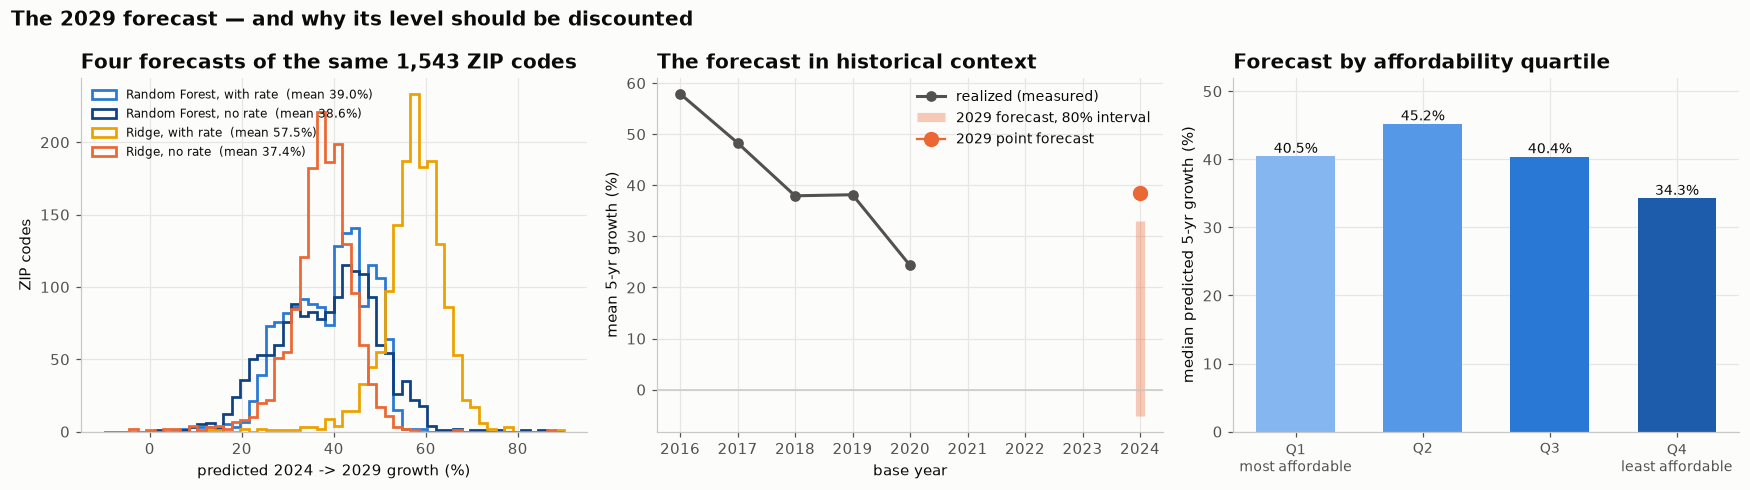

In [29]:
# ---- Figure 9: forecast distribution and the extrapolation gap ----------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

ax = axes[0]
bins = np.linspace(-10, 90, 55)
for (name, p), color in zip(fc_preds.items(), [BLUE, "#104281", "#eda100", ACCENT]):
    ax.hist(p, bins=bins, histtype="step", lw=1.8, color=color, label=f"{name}  (mean {p.mean():.1f}%)")
ax.set_xlabel("predicted 2024 -> 2029 growth (%)")
ax.set_ylabel("ZIP codes")
ax.legend(fontsize=8)
ax.set_title("Four forecasts of the same 1,543 ZIP codes")

ax = axes[1]
hist_mean = panel.groupby("base_year")[TARGET].mean()
ax.plot(hist_mean.index, hist_mean.values, marker="o", color=GRAY, lw=2, label="realized (measured)")
pt = forecast["predicted_5yr_growth_pct"].mean()
# Drawn as an explicit segment, not an errorbar: the 80% interval lies entirely BELOW the point
# estimate, because both out-of-time residual quantiles are negative. That asymmetry is the result.
ax.vlines(2024, pt + q10, pt + q90, color=ACCENT, lw=6, alpha=0.35,
          label="2029 forecast, 80% interval")
ax.plot([2024], [pt], marker="o", color=ACCENT, markersize=9, label="2029 point forecast")
ax.axhline(0, color="#c9c8c3", lw=1)
ax.set_xlabel("base year"); ax.set_ylabel("mean 5-yr growth (%)")
ax.set_title("The forecast in historical context")
ax.legend(fontsize=9)

ax = axes[2]
q = forecast.copy()
q["afford_group"] = pd.qcut(q["mortgage_to_income_ratio"], 4,
                            labels=["Q1\nmost affordable", "Q2", "Q3", "Q4\nleast affordable"])
grp = q.groupby("afford_group", observed=True)["predicted_5yr_growth_pct"].median()
ax.bar(range(4), grp.values, color=YEAR_COLORS[:4], width=0.62)
for i, v in enumerate(grp.values):
    ax.text(i, v + 0.5, f"{v:.1f}%", ha="center", fontsize=9)
ax.set_xticks(range(4)); ax.set_xticklabels(grp.index, fontsize=9)
ax.set_ylabel("median predicted 5-yr growth (%)")
ax.set_ylim(0, 52)
ax.set_title("Forecast by affordability quartile")

fig.suptitle("The 2029 forecast — and why its level should be discounted", x=0.005, ha="left",
             fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "fig09_forecast")
plt.show()

In [30]:
# ---- Forecast broken out by affordability group -------------------------------------------------
forecast["affordability_group"] = pd.qcut(
    forecast["mortgage_to_income_ratio"], 4,
    labels=["Q1 most affordable", "Q2", "Q3", "Q4 least affordable"])

by_afford = forecast.groupby("affordability_group", observed=True).agg(
    zips=("zip_code", "size"),
    median_mortgage_to_income=("mortgage_to_income_ratio", "median"),
    median_value_2024=("current_home_value", "median"),
    median_predicted_growth=("predicted_5yr_growth_pct", "median"),
    median_value_2029=("predicted_home_value_2029", "median"),
)
by_afford.round(2)

,zips,median_mortgage_to_income,median_value_2024,median_predicted_growth,median_value_2029
affordability_group,,,,,
Q1 most affordable,386,0.300,"380,752.900",40.450,"525,666.670"
Q2,386,0.400,"575,286.640",45.220,"797,512.000"
Q3,385,0.540,"902,044.410",40.400,"1,283,241.790"
Q4 least affordable,386,0.750,"1,289,035.220",34.280,"1,682,214.370"


**The primary predictor shows up in the forecast, as it should.** The least affordable quartile —
where a modelled mortgage payment consumes a median **75%** of monthly household income — carries the
**lowest** predicted growth (34.3%), and the gap to Q2 is **11 points**. The affordability-constraint
association that Section 6 identified as primary is what drives the spread of this forecast.

Q1 is slightly below Q2 rather than highest, which is worth not over-reading: the most affordable
quartile contains many very small rural ZIP codes where `population` — the other primary predictor —
pulls the prediction the other way.

In [31]:
cols = ["zip_code", "city", "county", "current_home_value", "predicted_5yr_growth_pct",
        "predicted_home_value_2029", "predicted_growth_lo", "predicted_growth_hi"]
print("TOP 20 predicted five-year growth (2024 -> 2029)")
forecast.nlargest(20, "predicted_5yr_growth_pct")[cols].reset_index(drop=True).round(1)

TOP 20 predicted five-year growth (2024 -> 2029)


,zip_code,city,county,current_home_value,predicted_5yr_growth_pct,predicted_home_value_2029,predicted_growth_lo,predicted_growth_hi
0,93562,NaN,Kern County,"71,026.200",85.500,"131,782.800",41.900,80.000
1,93516,Boron,Kern County,"179,083.900",81.800,"325,568.800",38.200,76.200
2,93523,Edwards,Kern County,"212,235.400",75.500,"372,400.300",31.800,69.900
3,95422,Clearlake,Lake County,"221,614.300",72.200,"381,607.000",28.600,66.600
4,92398,Daggett,San Bernardino County,"186,777.700",71.500,"320,239.900",27.800,65.900
5,93706,Fresno,Fresno County,"283,272.000",67.700,"475,041.400",24.100,62.100
6,92347,Hinkley,San Bernardino County,"147,860.800",67.400,"247,497.200",23.800,61.800
7,96113,Herlong,Lassen County,"125,877.000",65.500,"208,281.100",21.800,59.900
8,93268,Taft,Kern County,"216,687.700",62.600,"352,254.600",18.900,57.000
9,95351,Modesto,Stanislaus County,"383,516.100",61.400,"618,810.300",17.700,55.800


In [32]:
print("BOTTOM 20 predicted five-year growth (2024 -> 2029)")
forecast.nsmallest(20, "predicted_5yr_growth_pct")[cols].reset_index(drop=True).round(1)

BOTTOM 20 predicted five-year growth (2024 -> 2029)


,zip_code,city,county,current_home_value,predicted_5yr_growth_pct,predicted_home_value_2029,predicted_growth_lo,predicted_growth_hi
0,90021,Los Angeles,Los Angeles County,"914,050.600",2.600,"937,582.200",-41.100,-3.000
1,90013,Los Angeles,Los Angeles County,"650,659.900",8.000,"702,654.400",-35.600,2.400
2,90008,Los Angeles,Los Angeles County,"1,148,123.800",9.400,"1,256,196.500",-34.200,3.900
3,95560,Redway,Humboldt County,"391,009.100",10.000,"429,931.800",-33.700,4.400
4,90004,Los Angeles,Los Angeles County,"1,506,040.400",10.400,"1,662,160.900",-33.300,4.800
5,90005,Los Angeles,Los Angeles County,"969,513.200",10.900,"1,075,014.100",-32.800,5.300
6,95930,Clipper Mills,Butte County,"268,860.600",11.000,"298,503.700",-32.600,5.500
7,94569,Port Costa,Contra Costa County,"699,902.700",11.200,"777,983.300",-32.500,5.600
8,95039,Moss Landing,Monterey County,"1,119,129.900",11.300,"1,245,782.800",-32.300,5.800
9,90038,Los Angeles,Los Angeles County,"1,138,348.700",11.700,"1,271,297.000",-32.000,6.100


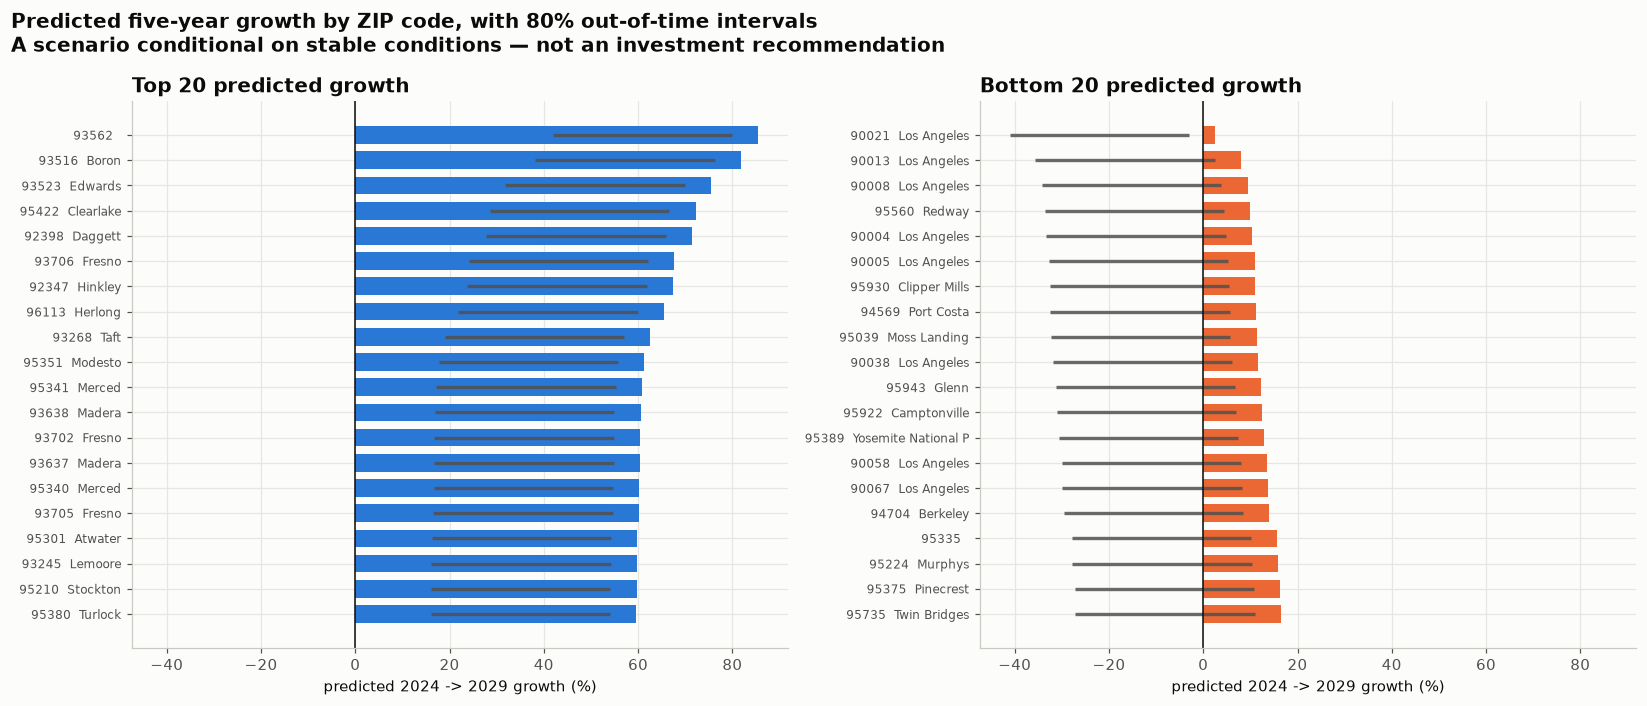

In [33]:
# ---- Figure 10: top / bottom 20 ------------------------------------------------------------------
top = forecast.nlargest(20, "predicted_5yr_growth_pct").iloc[::-1]
bot = forecast.nsmallest(20, "predicted_5yr_growth_pct").iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharex=True)
for ax, d, color, title in [
    (axes[0], top, BLUE, "Top 20 predicted growth"),
    (axes[1], bot, ACCENT, "Bottom 20 predicted growth"),
]:
    lbl = [f"{z}  {c if isinstance(c, str) else ''}"[:26] for z, c in zip(d["zip_code"], d["city"])]
    ax.barh(range(len(d)), d["predicted_5yr_growth_pct"], color=color, height=0.7)
    # The 80% interval sits entirely below the point estimate, so it is drawn as a segment rather
    # than as error bars around the bar tip.
    ax.hlines(range(len(d)), d["predicted_growth_lo"], d["predicted_growth_hi"],
              color=GRAY, lw=2.2, alpha=0.85)
    ax.axvline(0, color="#0b0b0b", lw=1)
    ax.set_yticks(range(len(d))); ax.set_yticklabels(lbl, fontsize=8)
    ax.set_xlabel("predicted 2024 -> 2029 growth (%)")
    ax.set_title(title)

fig.suptitle("Predicted five-year growth by ZIP code, with 80% out-of-time intervals\n"
             "A scenario conditional on stable conditions — not an investment recommendation",
             x=0.005, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "fig10_forecast_top_bottom")
plt.show()

## 8.4 What the ranking says — and the warning that goes with it

The predicted leaders are **inland and high-desert markets** — Kern County (93562, 93516 Boron, 93523
Edwards, 93268 Taft), Lake County (95422 Clearlake), San Bernardino desert ZIPs (92398 Daggett, 92347
Hinkley) and Central Valley ZIPs (93706 Fresno, 95351 Modesto). Median 2024 values there run
**$71k–$383k**.

The predicted laggards are **expensive urban Los Angeles ZIP codes** — 90021, 90013, 90008, 90004,
90005, 90038 — with values from **$650k to $1.5M**.

**This is the affordability-constraint association restated**, and it is internally consistent with
Section 6: the primary predictor has a negative sign, so the model places the ZIP codes with the most
room relative to local income at the top.

> ### Warnings that must accompany this table
>
> 1. **This is a scenario conditional on stable conditions, not a forecast of what will happen, and
>    under no reading an investment recommendation.** Every interval crosses or approaches zero.
> 2. **The level is not trustworthy** (Section 8.3). The *ranking* is the part supported by evidence,
>    and even that rests on a test-year Spearman of ~0.4.
> 3. **Small-population ZIP codes dominate the top of the list.** 93562 has a four-figure population;
>    a handful of transactions can move its ZHVI. The bottom-20 list is drawn from far larger, more
>    liquid markets and is correspondingly more stable.
> 4. **A high predicted percentage on a low base is a small dollar move.** 93562 at +85.5% gains
>    **$61k**; 90004 at +10.4% gains **$156k**.
> 5. **The model has only ever seen a boom.** Every training window contains the 2020–2022 surge.

In [34]:
OUT_FC = PROC / "forecast_2029_by_zip.csv"
out_cols = ["zip_code", "city", "county", "base_year", "current_home_value",
            "mortgage_to_income_ratio", "price_to_income_ratio", "affordability_group",
            "predicted_5yr_growth_pct", "predicted_growth_lo", "predicted_growth_hi",
            "predicted_home_value_2029", "predicted_value_2029_lo", "predicted_value_2029_hi"]
forecast[out_cols].to_csv(OUT_FC, index=False)
print(f"wrote {OUT_FC.relative_to(ROOT)}  ({len(forecast):,} rows)")
print(f"figures written: {len(sorted(FIGURES.glob('*.png')))}")
for f in sorted(FIGURES.glob("*.png")):
    print("  ", f.name)

wrote data/processed/forecast_2029_by_zip.csv  (1,543 rows)
figures written: 9
   fig01_model_comparison.png
   fig02_actual_vs_predicted.png
   fig03_residuals.png
   fig05_regime_shift.png
   fig06_relative_target.png
   fig07_feature_importance.png
   fig08_listings_ablation.png
   fig09_forecast.png
   fig10_forecast_top_bottom.png


---
# 9. Summary

## 9.1 What was built

15 features (D1's 12 core + 3 engineered affordability measures) → a **temporal** train/validation/test
split by base year → four models (Baseline, Ridge, Random Forest, Gradient Boosting), each scaled inside
a `Pipeline` and cross-validated with `GroupKFold` on `base_year`.

## 9.2 Headline results

| Model | CV RMSE | Val RMSE | Test RMSE | Test MAE | Test R² |
|---|---|---|---|---|---|
| Baseline (mean) | 22.33 | 21.38 | 29.28 | 24.78 | −1.88 |
| Ridge | 17.76 | 20.97 | 40.52 | 37.17 | −4.51 |
| Random Forest | 18.06 | 19.43 | 33.87 | 29.50 | −2.85 |
| Gradient Boosting | **17.71** | **19.04** | 35.50 | 31.42 | −3.23 |

**In cross-validation and on the validation year, every model beats the baseline — Gradient Boosting by
21%. On the 2020 test year every model, including the baseline, posts a large negative R².**

## 9.3 The diagnosis

**65–81% of the test error is a single constant level shift.** Mean realized growth falls 57.9% → 24.3%
across the panel; the models trained on a 48% world were tested on a 24% world.

Three independent lines of evidence confirm this rather than a coding fault:

1. **The baseline fails too (−1.88).** A constant predictor has no coefficients to get wrong.
2. **Debiasing restores normality.** Subtract the mean residual and RMSE lands at 17.3–17.6 against an
   actual standard deviation of 17.27 — and the residual plots become textbook.
3. **Redefining the target as growth relative to the year's median makes the models work.** Same rows,
   same features, same folds: Random Forest reaches **CV RMSE 15.20, validation R² +0.29, test R² +0.12,
   test Spearman +0.41.**

> **The models cannot predict how much California housing appreciates — that is set by a macro regime no
> ZIP-code feature can see. They can, modestly, predict which ZIP codes appreciate more than others.**

## 9.4 Primary and secondary predictors

Established by **three** cross-checked methods plus a sign-stability test across all five base years.

| Rank | Predictor | Evidence |
|---|---|---|
| **Primary** | **`population`** (urban scale block, grouped mean **1.541**) | Ridge +1.66; ranked **first** by Random Forest permutation importance in both held-out years; positive in all five base years and strengthening (+0.054 → +0.285) |
| **Primary** | **Affordability block** (grouped mean **1.462**) — `mortgage_to_income_ratio` (−2.57, the largest coefficient in the model), `price_to_income_ratio` (−2.24), `price_to_rent_ratio` (−2.16) | Ranked **first** by Ridge in both held-out years; **negative in all five base years** |
| Secondary | `home_value_1yr_growth_pct` | Coefficient and permutation rank 4, but the sign **oscillates** (+0.139, +0.409, −0.116, −0.001, +0.304) |
| Secondary | `current_home_value`, `bachelor_degree_pct`, `median_household_income`, `median_gross_rent` | Large coefficients, but every one **flips sign** between 2016 and 2020; block mean only 0.211 |
| Weak | `unemployment_rate`, `population_growth_pct`, `rent_to_income_ratio` | Low and unstable; the labor-market block scores **negative** |
| **Control, not a predictor** | `mortgage_rate` | **Impurity importance rank 2 of 15; permutation importance on the test set exactly 0.000** |

**A caveat on D2's engineered feature.** `mortgage_to_income_ratio` carries the largest standardized
coefficient in the model — but Section 1.2 showed it is a **within-year rescaling of
`price_to_income_ratio`**, because `mortgage_rate` is constant within a base year. Their within-year
correlations with the target are identical to three decimals. It earns its coefficient, and it **did not
add cross-sectional information D1 lacked.** That is a negative result about the feature the plan
expected to be most interesting, and it is reported as such.

## 9.5 Listings

On **identical rows with identical folds**, adding `inventory_per_1k_housing_units` cuts leave-one-year-out
CV RMSE by **0.47 (Ridge)** and **0.32 (Random Forest)** — a real, replicated **2–3% error reduction**,
and nonlinear.

The short-run indicators do not survive the horizon: `price_cut_pct` correlates **+0.260** with raw growth
and **+0.049** with relative growth — almost all of its apparent signal was a base-year effect. The
four-feature complete case keeps only **1,583 of 4,539 rows (34.9%)** with **4.2× the median population**
and **+10 points of growth**, so it is reported as a robustness check with the bias stated, never as a
headline. **A listings-availability flag is never used as a predictor**: it measures Zillow's reporting
behaviour, not the housing market.

## 9.6 The 2029 forecast

Point forecast: **+39.5% median growth**, median California ZIP $723,096 → **$1,017,114**.
80% out-of-time interval: **−4.1% to +34.0%**, i.e. **$699,947 to $976,099**.

The point estimate lies **above** its own interval, because it inherits a boom-era mean while the
interval is calibrated on the one occasion the model met a post-boom year. **The interval is the more
credible object**, and the honest summary is *roughly flat to moderately up.*

Both failure modes of extrapolation are on display: **Random Forest's forecast moves 0.40 points when the
rate feature is added or removed** (it clamps to the training boundary), while **Ridge moves +20.07 points
in the wrong direction** (it projects a line 48% beyond the data and concludes that a 6.72% mortgage rate
implies *more* appreciation).

Ranking: inland Kern/Lake/San Bernardino/Central Valley ZIPs on top, expensive Los Angeles ZIPs at the
bottom — the affordability association restated. Predicted growth by affordability quartile falls from
**45.2% (Q2)** to **34.3% (Q4, least affordable)**.

## 9.7 Challenges

| Challenge | Response |
|---|---|
| **Overlapping outcome windows** make rows non-independent | Temporal split by base year; `GroupKFold(groups=base_year)`; no plain `KFold` anywhere |
| **Regime shift 2016→2020** breaks the absolute target out-of-time | Diagnosed rather than hidden; bias/spread decomposition; relative-target diagnostic isolates the learnable part |
| **`mortgage_rate` is national** — five values, confounded with `base_year` | Shown to be actively harmful out-of-time; removed from the primary models; the impurity-vs-permutation contrast documented |
| **Severe collinearity** (income ↔ rent +0.84) breaks per-feature importance | Grouped permutation importance over correlated blocks; Ridge for stable coefficients |
| **Listings coverage is non-random** and correlates with the outcome | Same-rows ablation; primary experiment on the 75%-coverage feature; availability flag never used as a predictor |
| **The 2024 rate is outside the training range** | Forecast produced twice, with and without rate features; both extrapolation failure modes reported; intervals from out-of-time residuals |
| Target-derived flags (`is_growth_outlier`) look like data-quality columns | Explicitly excluded from `FEATURES` and asserted against |

## 9.8 What D3 should carry forward

1. **The absolute five-year growth level is not predictable from cross-sectional features.** Any
   classification target should be defined **relative to the base year** — e.g. "did this ZIP beat its
   year's median?" — or it will inherit this same regime problem.
2. **Keep the temporal split.** It is the only thing standing between this project and a meaningless R².
3. **Affordability ratios and `population` are the features to build on.** The affluence-level features
   are regime-dependent and should be treated with suspicion.
4. **Leave `mortgage_rate` out**, or keep it only as an explicit market-cycle control.

---

### A closing note on language

Every relationship reported here is an **association measured in observational data**. High
`mortgage_to_income_ratio` ZIP codes subsequently grew more slowly than their year's median. This
notebook does not claim that unaffordability *caused* slower growth, and nothing in a regression on this
panel could establish that.